In [ ]:
# =============================
# Wireless Channel Simulation with Sionna RT
# Single Frequency + Single Scenario per run
# Includes:
# - Ray-Tracing with Dynamic Large-Vehicle Blockage (Digital Twin Scenario)
# - Path Loss metrics, Delay-Doppler Heatmaps, RMS Spreads
# - Full Dataframe Aggregation and ZIP Download
# =============================

# =========================================================
# SECTION 1: ENVIRONMENT SETUP
# =========================================================

try:
    import tensorflow as tf
except ImportError:
    import os
    os.system("pip install tensorflow==2.19")
    import tensorflow as tf

try:
    import sionna
except ImportError:
    import os
    os.system("pip install sionna")
    import sionna

try:
    import mitsuba as mi
except ImportError:
    import os
    os.system("pip install mitsuba")
    import mitsuba as mi

try:
    import drjit as dr
except ImportError:
    import os
    os.system("pip install drjit")
    import drjit as dr

# =========================================================
# SECTION 2: CORE IMPORTS
# =========================================================

import os
import sys
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

sys.stdout.flush()
no_preview = True  # Toggle to False to use the preview widget

# =========================================================
# SECTION 3: SIONNA RT IMPORTS
# =========================================================

import sionna.rt
from sionna.rt import (
    load_scene, PlanarArray, Transmitter, Receiver, Camera,
    PathSolver, subcarrier_frequencies, SceneObject, RadioMaterial
)


In [ ]:

# =========================================================
# SECTION 4: USER CONFIGURATION
# =========================================================

SCENE_XML = "/content/untitled.xml"

RUN_FREQUENCY_GHZ = 28
SCENARIO_NAME = "40-30_with_Blocker"
CAR1_SPEED_MPS = 11.11   # ~ 40 km/h
CAR2_SPEED_MPS = 8.33    # ~ 30 km/h

# [NEW]: إعدادات الشاحنة الحاجزة (Blocker)
BLOCKER_OFFSET_M = 4.0  # مسافة 59 أمتار فقط بين سيارة الإرسال والشاحنة

RESULTS_ROOT = "./results_v2v_single_run"

dt = 0.5  # seconds

num_subcarriers = 1024
subcarrier_spacing = 30e3
ofdm_symbol_duration = 1 / subcarrier_spacing
num_ofdm_symbols_dd = 256

num_short_steps = 25
dt_short = ofdm_symbol_duration

MAX_DEPTH = 6
MAX_NUM_PATHS_PER_SRC = 10**6
SAMPLES_PER_SRC = 10**6
SEED = 41

car1_start = np.array([220.0, -150.0, 0.1], dtype=float)
car1_end   = np.array([-10.0,  70.0, 0.1], dtype=float)

car2_start = np.array([-10.0,  70.0, 0.1], dtype=float)
car2_end   = np.array([220.0, -150.0, 0.1], dtype=float)

antenna_offset1 = np.array([0.0, 0.0, 1.8], dtype=float)
antenna_offset2 = np.array([0.0, 0.0, 1.5], dtype=float)

# =========================================================
# SECTION 5: HELPER FUNCTIONS
# =========================================================

SINGLE_COL_W = 3.4
DOUBLE_COL_W = 7.0

def ensure_dir(path):
    os.makedirs(path, exist_ok=True)
    return path

def set_publication_style():
    plt.rcParams.update({
        "font.family": "serif",
        "font.size": 9,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "axes.linewidth": 0.8,
        "lines.linewidth": 1.2,
        "lines.markersize": 3.5,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "xtick.minor.width": 0.6,
        "ytick.minor.width": 0.6,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.major.size": 4,
        "ytick.major.size": 4,
        "xtick.minor.size": 2,
        "ytick.minor.size": 2,
        "legend.frameon": False,
        "axes.grid": False,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.02,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    })

def save_plot(fig, filepath_no_ext, dpi=600):
    fig.savefig(filepath_no_ext + ".svg", dpi=dpi)
    fig.savefig(filepath_no_ext + ".png", dpi=dpi)
    plt.close(fig)

def save_plot_3d(fig, filepath_no_ext, dpi=600):
    fig.savefig(filepath_no_ext + ".svg", dpi=dpi, bbox_inches=None, pad_inches=0.10)
    fig.savefig(filepath_no_ext + ".png", dpi=dpi, bbox_inches=None, pad_inches=0.10)
    plt.close(fig)

def style_2d_axis(ax, xlabel=None, ylabel=None, add_minor=True):
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    if add_minor:
        ax.minorticks_on()
    ax.tick_params(axis="both", which="major", direction="in", top=True, right=True)
    ax.tick_params(axis="both", which="minor", direction="in", top=True, right=True)
    for spine in ax.spines.values():
        spine.set_linewidth(0.8)

def style_3d_axis(ax, xlabel=None, ylabel=None, zlabel=None):
    if xlabel is not None:
        ax.set_xlabel(xlabel, labelpad=12)
    if ylabel is not None:
        ax.set_ylabel(ylabel, labelpad=14)
    if zlabel is not None:
        ax.set_zlabel(zlabel, labelpad=10)
    ax.tick_params(axis="x", which="major", pad=2)
    ax.tick_params(axis="y", which="major", pad=2)
    ax.tick_params(axis="z", which="major", pad=4)
    ax.xaxis.pane.set_alpha(0.0)
    ax.yaxis.pane.set_alpha(0.0)
    ax.zaxis.pane.set_alpha(0.0)
    ax.grid(True, alpha=0.25)

def add_panel_label(ax, label):
    ax.text(0.02, 0.98, label, transform=ax.transAxes, ha="left", va="top", fontsize=9, fontweight="bold")

def to_db(x):
    return 10 * tf.math.log(x) / tf.math.log(10.0)

def to_db10_np(x, eps=1e-30):
    x = np.asarray(x, dtype=float)
    return 10 * np.log10(np.maximum(x, eps))

def to_db20_np(x, eps=1e-30):
    x = np.asarray(x)
    return 20 * np.log10(np.maximum(np.abs(x), eps))

def prepare_delay_doppler_display(h_dd, delay_bins_ns, doppler_bins, delay_mask, dynamic_range_db=45.0, doppler_stride=2, delay_stride=1):
    Z_db = to_db20_np(h_dd[:, delay_mask])
    Z_db = np.asarray(Z_db, dtype=float)
    Z_db[~np.isfinite(Z_db)] = np.nan

    if np.all(np.isnan(Z_db)):
        vmax = -60.0
        vmin = vmax - dynamic_range_db
        Z_db = np.full_like(Z_db, vmin)
    else:
        vmax = float(np.nanmax(Z_db))
        vmin = float(vmax - dynamic_range_db)
        Z_db = np.clip(Z_db, vmin, vmax)

    x = np.asarray(delay_bins_ns[delay_mask], dtype=float)
    y = np.asarray(doppler_bins, dtype=float)

    X, Y = np.meshgrid(x, y)
    Xp = X[::doppler_stride, ::delay_stride]
    Yp = Y[::doppler_stride, ::delay_stride]
    Zp = Z_db[::doppler_stride, ::delay_stride]

    return {"Z_db": Z_db, "X": X, "Y": Y, "Xp": Xp, "Yp": Yp, "Zp": Zp, "x": x, "y": y, "vmin": vmin, "vmax": vmax}

def compute_2d_distance(point_a, point_b):
    return np.linalg.norm(point_a[:2] - point_b[:2])

def compute_3d_distance(point_a, point_b):
    return np.linalg.norm(point_a - point_b)

def compute_vertical_difference(point_a, point_b):
    return point_a[2] - point_b[2]

def weighted_mean_and_rms(values, weights):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)

    mask = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    if not np.any(mask):
        return np.nan, np.nan

    v = values[mask]
    w = weights[mask]
    w = w / np.sum(w)

    mu = np.sum(w * v)
    rms = np.sqrt(np.sum(w * (v - mu) ** 2))
    return mu, rms

def nmse_db(h_ref, h_est, eps=1e-30):
    num = np.sum(np.abs(h_ref - h_est) ** 2)
    den = np.sum(np.abs(h_ref) ** 2) + eps
    return 10 * np.log10(num / den + eps)

def compute_delay_doppler_from_h(h_tf, subcarrier_spacing):
    h_tf = np.squeeze(h_tf)
    num_time_steps, num_subcarriers_local = h_tf.shape

    ofdm_symbol_duration_local = 1 / subcarrier_spacing
    delay_resolution = ofdm_symbol_duration_local / num_subcarriers_local
    doppler_resolution = subcarrier_spacing / num_time_steps

    h_tf = np.fft.fftshift(h_tf, axes=1)
    h_delay = np.fft.ifft(h_tf, axis=1, norm="ortho")
    h_dd = np.fft.fft(h_delay, axis=0, norm="ortho")
    h_dd = np.fft.fftshift(h_dd, axes=0)

    doppler_bins = np.arange(
        -num_time_steps / 2 * doppler_resolution,
         num_time_steps / 2 * doppler_resolution,
         doppler_resolution
    )
    delay_bins_ns = np.arange(0, num_subcarriers_local * delay_resolution, delay_resolution) / 1e-9

    return h_dd, delay_bins_ns, doppler_bins

def build_delay_doppler_at_step(scene, step_idx, car1_pos_history, car2_pos_history, antenna_offset1, antenna_offset2, car1_velocity, car2_velocity, p_solver, solver_kwargs, frequencies, ofdm_symbol_duration, subcarrier_spacing, num_ofdm_symbols_dd):
    scene.get("car1").position = car1_pos_history[step_idx].tolist()
    scene.get("car2").position = car2_pos_history[step_idx].tolist()

    # [NEW]: Update Blocker for Delay-Doppler snapshots
    car1_dir = car1_velocity / np.linalg.norm(car1_velocity)
    scene.get("blocker").position = (car1_pos_history[step_idx] + car1_dir * BLOCKER_OFFSET_M).tolist()

    scene.get("tx_car1").position = (car1_pos_history[step_idx] + antenna_offset1).tolist()
    scene.get("rx_car2").position = (car2_pos_history[step_idx] + antenna_offset2).tolist()

    scene.get("car1").velocity = car1_velocity.tolist()
    scene.get("car2").velocity = car2_velocity.tolist()
    scene.get("blocker").velocity = car1_velocity.tolist()

    scene.get("tx_car1").velocity = car1_velocity.tolist()
    scene.get("rx_car2").velocity = car2_velocity.tolist()

    paths_phase = p_solver(scene=scene, **solver_kwargs)
    h_dop_phase = paths_phase.cfr(frequencies=frequencies, sampling_frequency=1 / ofdm_symbol_duration, num_time_steps=num_ofdm_symbols_dd, normalize_delays=False, out_type="numpy")
    h_dop_phase = np.squeeze(h_dop_phase)

    h_dd_phase, delay_bins_ns_phase, doppler_bins_phase = compute_delay_doppler_from_h(h_dop_phase, subcarrier_spacing)
    max_delay_ns_phase = min(800, delay_bins_ns_phase[-1])
    delay_mask_phase = delay_bins_ns_phase <= max_delay_ns_phase

    return {"h_dop": h_dop_phase, "h_dd": h_dd_phase, "delay_bins_ns": delay_bins_ns_phase, "doppler_bins": doppler_bins_phase, "delay_mask": delay_mask_phase, "max_delay_ns": max_delay_ns_phase}

set_publication_style()

# =========================================================
# SECTION 6: SCENE CONFIGURATION
# =========================================================

scene = sionna.rt.load_scene(SCENE_XML, merge_shapes=True)
camera = Camera(position=[0, -100, 1500], look_at=[0, 0, 5])

# =========================================================
# SECTION 8 & 9: MATERIALS
# =========================================================

Brick = RadioMaterial(name="Brick-material", relative_permittivity=5.240, conductivity=0.626, thickness=0.100, color=(0.8, 0.8, 0.8))
if "Brick-material" not in scene.radio_materials: scene.add(Brick)
if "no-name-2" in scene.objects: scene.objects["no-name-2"].radio_material = "Brick-material"
if "itu_brick" in scene.radio_materials: scene.remove("itu_brick")

MetalCar = RadioMaterial(name="Metal-car-material", relative_permittivity=1.0, conductivity=1e7, thickness=0.02, color=(1.0, 0.0, 0.0))
if "Metal-car-material" not in scene.radio_materials: scene.add(MetalCar)

# =========================================================
# SECTION 10 & 11: ADD CARS AND BLOCKER
# =========================================================

if "car1" in scene.objects: scene.remove("car1")
car1 = SceneObject(fname=sionna.rt.scene.low_poly_car, name="car1", radio_material=MetalCar)
scene.edit(add=car1)
scene.get("car1").position = mi.Point3f(220.0, -150.0, 0.1)
scene.get("car1").orientation = mi.Point3f(0.0, 0.0, 0.0)
scene.get("car1").scaling = 1

if "car2" in scene.objects: scene.remove("car2")
car2 = SceneObject(fname=sionna.rt.scene.low_poly_car, name="car2", radio_material=MetalCar)
scene.edit(add=car2)
scene.get("car2").position = mi.Point3f(-10.0, 70.0, 0.1)
scene.get("car2").orientation = mi.Point3f(0.0, 0.0, np.pi)
scene.get("car2").scaling = 1

# [NEW]: Add Blocker (Truck/Bus size)
if "blocker" in scene.objects: scene.remove("blocker")
blocker = SceneObject(fname=sionna.rt.scene.low_poly_car, name="blocker", radio_material=MetalCar)
scene.edit(add=blocker)
scene.get("blocker").orientation = mi.Point3f(0.0, 0.0, 0.0)
scene.get("blocker").scaling = 3.0  # تكبير 5 أضعاف

In [ ]:
# =========================================================
# SECTION 13 & 14: TX/RX ARRAYS
# =========================================================

scene.frequency = RUN_FREQUENCY_GHZ * 1e9
scene.bandwidth = 1e9

scene.tx_array = PlanarArray(num_rows=1, num_cols=1, vertical_spacing=0.5, horizontal_spacing=0.5, pattern="iso", polarization="V")
scene.rx_array = PlanarArray(num_rows=1, num_cols=1, vertical_spacing=0.5, horizontal_spacing=0.5, pattern="iso", polarization="V")

tx_initial_pos = (car1_start + antenna_offset1).tolist()
rx_initial_pos = (car2_start + antenna_offset2).tolist()

if "tx_car1" in scene.transmitters: scene.remove("tx_car1")
if "rx_car2" in scene.receivers: scene.remove("rx_car2")

scene.add(Transmitter(name="tx_car1", power_dbm=45, position=tx_initial_pos, color=(0.0, 1.0, 0.0), display_radius=5))
scene.add(Receiver(name="rx_car2", position=rx_initial_pos, color=(0.0, 0.0, 1.0), display_radius=5))

# =========================================================
# SECTION 16: VEHICLE TRAJECTORIES
# =========================================================

car1_direction_vector = car1_end - car1_start
car2_direction_vector = car2_end - car2_start

car1_distance_total = np.linalg.norm(car1_direction_vector)
car2_distance_total = np.linalg.norm(car2_direction_vector)

car1_direction_unit = car1_direction_vector / car1_distance_total
car2_direction_unit = car2_direction_vector / car2_distance_total

# [NEW]: Blocker initial position
blocker_start = car1_start + car1_direction_unit * BLOCKER_OFFSET_M
scene.get("blocker").position = blocker_start.tolist()

car1_step_distance = CAR1_SPEED_MPS * dt
car2_step_distance = CAR2_SPEED_MPS * dt

car1_step_vector = car1_direction_unit * car1_step_distance
car2_step_vector = car2_direction_unit * car2_step_distance

car1_num_steps = int(np.ceil(car1_distance_total / car1_step_distance))
car2_num_steps = int(np.ceil(car2_distance_total / car2_step_distance))
num_steps = max(car1_num_steps, car2_num_steps)

car1_current = car1_start.copy()
car2_current = car2_start.copy()

car1_finished = False
car2_finished = False

# =========================================================
# SECTION 17: CHANNEL / RAY-TRACING SETTINGS
# =========================================================

car1_velocity = car1_direction_unit * CAR1_SPEED_MPS
car2_velocity = car2_direction_unit * CAR2_SPEED_MPS

scene.get("car1").velocity = car1_velocity.tolist()
scene.get("car2").velocity = car2_velocity.tolist()
scene.get("blocker").velocity = car1_velocity.tolist() # [NEW]

scene.get("tx_car1").velocity = car1_velocity.tolist()
scene.get("rx_car2").velocity = car2_velocity.tolist()

p_solver = PathSolver()
solver_kwargs = dict(max_depth=MAX_DEPTH, max_num_paths_per_src=MAX_NUM_PATHS_PER_SRC, samples_per_src=SAMPLES_PER_SRC, los=False, specular_reflection=True, diffuse_reflection=True, refraction=False, diffraction=False, edge_diffraction=False, synthetic_array=True, seed=SEED)

all_steps_dfs = []
summary_rows = []
path_cloud_rows = []

antenna_distance_2d_history = []
antenna_distance_3d_history = []
step_history = []
car1_pos_history = []
car2_pos_history = []
h_sim_steps = []

frequencies = subcarrier_frequencies(num_subcarriers, subcarrier_spacing)



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

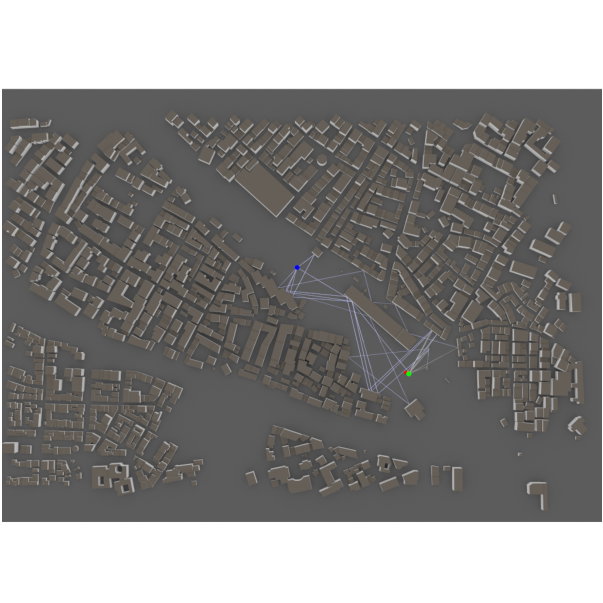

In [ ]:
# === Ray-Tracing Path Solver ===
# Initialize the path solver object to compute ray-traced paths
p_solver = PathSolver()
# Compute propagation paths based on the scene setup
paths = p_solver(scene=scene,      # The loaded 3D scene
    max_depth=6,                   # Maximum number of interactions (reflections/refractions)
    max_num_paths_per_src=10**6,     # Limit on total number of rays per transmitter
    samples_per_src=10**6,           # Number of rays sampled from the transmitter
    los=False,                      # Enable line-of-sight path calculation
    specular_reflection=True,      # Enable mirror-like (specular) reflections
    diffuse_reflection=True,       # Enable scattered (diffuse) reflections
    refraction=False,              # Disable refraction (for glass/translucent materials)
    diffraction=False,
    edge_diffraction=False,
    synthetic_array=True,          # Enable synthetic MIMO array processing
    seed=41,                        # Set random seed for reproducibility
)

img = scene.render(
    camera=camera,
    paths=paths,
    clip_at=1024,
    resolution=[1024, 1024],
    num_samples=1024
)

# جعل الصورة بدون حواف
img.subplots_adjust(
    left=0,
    right=1,
    bottom=0,
    top=1
)

# حفظ بدقة عالية وبدون حواف بيضاء
img.savefig(
    "/content/ray_tracing_result.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0
)

# تحميل الصورة إلى الكمبيوتر
from google.colab import files
files.download("/content/ray_tracing_result.png")

In [ ]:
# =========================================================
# SECTION 18: MOTION LOOP + CHANNEL CALCULATIONS
# =========================================================

for step in range(num_steps + 1):
    current_time = step * dt
    print(f"\n================ STEP {step} | t = {current_time:.3f} s ================")

    # Update Positions
    scene.get("car1").position = car1_current.tolist()
    scene.get("car2").position = car2_current.tolist()

    # [NEW] Move blocker 5m ahead of Tx
    blocker_current = car1_current + car1_direction_unit * BLOCKER_OFFSET_M
    scene.get("blocker").position = blocker_current.tolist()

    scene.get("tx_car1").position = (car1_current + antenna_offset1).tolist()
    scene.get("rx_car2").position = (car2_current + antenna_offset2).tolist()

    tx0 = scene.get("tx_car1")
    rx0 = scene.get("rx_car2")
    tx0.look_at(rx0.position)
    rx0.look_at(tx0.position)

    car1_pos = np.array(scene.get("car1").position.numpy()).reshape(-1)
    car2_pos = np.array(scene.get("car2").position.numpy()).reshape(-1)
    tx_pos   = np.array(scene.get("tx_car1").position.numpy()).reshape(-1)
    rx_pos   = np.array(scene.get("rx_car2").position.numpy()).reshape(-1)

    car1_pos_history.append(car1_pos.copy())
    car2_pos_history.append(car2_pos.copy())

    vehicle_distance_2d = compute_2d_distance(car1_pos, car2_pos)
    vehicle_distance_3d = compute_3d_distance(car1_pos, car2_pos)
    vehicle_delta_z = compute_vertical_difference(car1_pos, car2_pos)

    antenna_distance_2d = compute_2d_distance(tx_pos, rx_pos)
    antenna_distance_3d = compute_3d_distance(tx_pos, rx_pos)
    antenna_delta_z = compute_vertical_difference(tx_pos, rx_pos)

    antenna_distance_2d_history.append(float(antenna_distance_2d))
    antenna_distance_3d_history.append(float(antenna_distance_3d))
    step_history.append(step)

    print(f"car1 position              : {car1_pos}")
    print(f"car2 position              : {car2_pos}")
    print(f"antenna_distance_3d        : {antenna_distance_3d:.9f} m")

    paths = p_solver(scene=scene, **solver_kwargs)
    valid_np = paths.valid.numpy()
    valid_any = (valid_np.size > 0) and np.any(valid_np)

    if not valid_any:
        print("No valid paths found in this step.")
        summary_rows.append({
            "Scenario": SCENARIO_NAME, "Frequency (GHz)": RUN_FREQUENCY_GHZ, "Step": step, "Time (s)": current_time,
            "Vehicle Distance 3D (m)": vehicle_distance_3d, "Vehicle Delta Z (m)": vehicle_delta_z,
            "Antenna Distance 3D (m)": antenna_distance_3d, "Antenna Delta Z (m)": antenna_delta_z,
            "Number of Paths": 0, "Min Delay (ns)": np.nan, "Max Delay (ns)": np.nan, "Mean Delay (ns)": np.nan,
            "Min Doppler (Hz)": np.nan, "Max Doppler (Hz)": np.nan, "Mean Doppler (Hz)": np.nan,
            "Path Gain Total (dB)": -np.inf, "Path Loss (dB)": np.inf,
            "TX Position": f"{tx_pos[0]}, {tx_pos[1]}, {tx_pos[2]}", "RX Position": f"{rx_pos[0]}, {rx_pos[1]}, {rx_pos[2]}",
        })
        step_df = pd.DataFrame([{
            "Scenario": SCENARIO_NAME, "Frequency (GHz)": RUN_FREQUENCY_GHZ, "Step": step, "Time (s)": current_time,
            "Receiver Index": 0, "Path Index": "Summary", "Valid Path": None, "Delay (s)": None,
            "Distance from Delay (m)": None, "AoA (rad)": None, "AoD (rad)": None, "ZoA (rad)": None,
            "ZoD (rad)": None, "Doppler (Hz)": None, "Real(a)": None, "Imag(a)": None, "Path Gain per path (watt)": None,
            "Path Gain per path (dB)": None, "Vehicle Distance 3D (m)": vehicle_distance_3d,
            "Vehicle Delta Z (m)": vehicle_delta_z, "Antenna Distance 3D (m)": antenna_distance_3d,
            "Antenna Delta Z (m)": antenna_delta_z, "TX Position": f"{tx_pos[0]}, {tx_pos[1]}, {tx_pos[2]}",
            "RX Position": f"{rx_pos[0]}, {rx_pos[1]}, {rx_pos[2]}", "TX Height (m)": tx_pos[2], "RX Height (m)": rx_pos[2],
            "Number of Paths": 0, "Min Delay (ns)": np.nan, "Max Delay (ns)": np.nan, "Mean Delay (ns)": np.nan,
            "Min Doppler (Hz)": np.nan, "Max Doppler (Hz)": np.nan, "Mean Doppler (Hz)": np.nan,
            "Path Gain Total (dB)": -np.inf, "Path Loss (dB)": np.inf,
        }])
        all_steps_dfs.append(step_df)
    else:
        h_step = np.squeeze(paths.cfr(frequencies=frequencies, sampling_frequency=1 / ofdm_symbol_duration, normalize_delays=False, out_type="numpy"), axis=(0, 1, 2, 3))
        h_sim_steps.append(h_step)

        a_step_np, _ = paths.cir(normalize_delays=True, out_type="numpy")
        all_rx_dfs = []

        for i in range(paths.num_rx):
            coef_real_full = np.asarray(paths.a[0].numpy()[i, 0, 0, 0, :]).reshape(-1)
            coef_imag_full = np.asarray(paths.a[1].numpy()[i, 0, 0, 0, :]).reshape(-1)
            tau_rx_full    = np.asarray(paths.tau[i, 0, :].numpy()).reshape(-1)
            AoA_full       = np.asarray(paths.phi_r[i, 0, :].numpy()).reshape(-1)
            AoD_full       = np.asarray(paths.phi_t[i, 0, :].numpy()).reshape(-1)
            ZoA_full       = np.asarray(paths.theta_r[i, 0, :].numpy()).reshape(-1)
            ZoD_full       = np.asarray(paths.theta_t[i, 0, :].numpy()).reshape(-1)
            doppler_full   = np.asarray(paths.doppler[i, 0, :].numpy()).reshape(-1)

            valid_rx = np.asarray(paths.valid.numpy()[i, 0, :]).astype(bool).reshape(-1)

            mask = valid_rx & ((coef_real_full != 0) | (coef_imag_full != 0))

            coef_real, coef_imag = coef_real_full[mask], coef_imag_full[mask]
            tau_rx, doppler = tau_rx_full[mask], doppler_full[mask]
            AoA, AoD, ZoA, ZoD = AoA_full[mask], AoD_full[mask], ZoA_full[mask], ZoD_full[mask]
            path_indices = np.where(mask)[0]
            num_paths = len(path_indices)

            path_power_linear = np.abs(coef_real + 1j * coef_imag) ** 2
            path_power_db = to_db10_np(path_power_linear)

            path_gain_db = to_db(tf.reduce_sum(tf.abs(tf.reduce_mean(a_step_np[i], axis=-3)) ** 2)).numpy()
            path_loss_db = -path_gain_db

            min_delay_ns = np.min(tau_rx) * 1e9 if num_paths > 0 else np.nan
            max_delay_ns = np.max(tau_rx) * 1e9 if num_paths > 0 else np.nan
            mean_delay_ns = np.mean(tau_rx) * 1e9 if num_paths > 0 else np.nan
            min_doppler_hz = np.min(doppler) if num_paths > 0 else np.nan
            max_doppler_hz = np.max(doppler) if num_paths > 0 else np.nan
            mean_doppler_hz = np.mean(doppler) if num_paths > 0 else np.nan

            for p_idx in range(num_paths):
                path_cloud_rows.append({
                    "Scenario": SCENARIO_NAME, "Frequency (GHz)": RUN_FREQUENCY_GHZ, "Step": step,
                    "Time (s)": current_time, "Delay (ns)": tau_rx[p_idx] * 1e9, "Doppler (Hz)": doppler[p_idx],
                    "Power (linear)": path_power_linear[p_idx], "Power (dB)": path_power_db[p_idx],
                    "Antenna Distance 3D (m)": antenna_distance_3d, "Vehicle Distance 3D (m)": vehicle_distance_3d,
                })

            df = pd.DataFrame({
                "Scenario": SCENARIO_NAME, "Frequency (GHz)": RUN_FREQUENCY_GHZ, "Step": step, "Time (s)": current_time,
                "Receiver Index": i, "Path Index": path_indices, "Valid Path": True, "Delay (s)": tau_rx,
                "Distance from Delay (m)": tau_rx * 3e8, "AoA (rad)": AoA, "AoD (rad)": AoD, "ZoA (rad)": ZoA,
                "ZoD (rad)": ZoD, "Doppler (Hz)": doppler, "Real(a)": coef_real, "Imag(a)": coef_imag,
                "Path Gain per path (watt)": path_power_linear, "Path Gain per path (dB)": path_power_db,
                "Vehicle Distance 3D (m)": vehicle_distance_3d, "Vehicle Delta Z (m)": vehicle_delta_z,
                "Antenna Distance 3D (m)": antenna_distance_3d, "Antenna Delta Z (m)": antenna_delta_z,
                "TX Position": f"{tx_pos[0]}, {tx_pos[1]}, {tx_pos[2]}", "RX Position": f"{rx_pos[0]}, {rx_pos[1]}, {rx_pos[2]}",
                "Path Loss (dB)": path_loss_db,
            })

            summary_row_df = pd.DataFrame([{
                "Scenario": SCENARIO_NAME, "Frequency (GHz)": RUN_FREQUENCY_GHZ, "Step": step, "Time (s)": current_time,
                "Receiver Index": i, "Path Index": "Summary", "Valid Path": None, "Delay (s)": None,
                "Distance from Delay (m)": None, "AoA (rad)": None, "AoD (rad)": None, "ZoA (rad)": None,
                "ZoD (rad)": None, "Doppler (Hz)": None, "Real(a)": None, "Imag(a)": None,
                "Path Gain per path (watt)": None, "Path Gain per path (dB)": None,
                "Vehicle Distance 3D (m)": vehicle_distance_3d, "Vehicle Delta Z (m)": vehicle_delta_z,
                "Antenna Distance 3D (m)": antenna_distance_3d, "Antenna Delta Z (m)": antenna_delta_z,
                "TX Position": f"{tx_pos[0]}, {tx_pos[1]}, {tx_pos[2]}", "RX Position": f"{rx_pos[0]}, {rx_pos[1]}, {rx_pos[2]}",
                "TX Height (m)": tx_pos[2], "RX Height (m)": rx_pos[2], "Number of Paths": num_paths,
                "Min Delay (ns)": min_delay_ns, "Max Delay (ns)": max_delay_ns, "Mean Delay (ns)": mean_delay_ns,
                "Min Doppler (Hz)": min_doppler_hz, "Max Doppler (Hz)": max_doppler_hz, "Mean Doppler (Hz)": mean_doppler_hz,
                "Path Gain Total (dB)": path_gain_db, "Path Loss (dB)": path_loss_db,
            }])
            df = pd.concat([df, summary_row_df], ignore_index=True)
            all_rx_dfs.append(df)

            summary_rows.append({
                "Scenario": SCENARIO_NAME, "Frequency (GHz)": RUN_FREQUENCY_GHZ, "Step": step, "Time (s)": current_time,
                "Vehicle Distance 3D (m)": vehicle_distance_3d, "Vehicle Delta Z (m)": vehicle_delta_z,
                "Antenna Distance 3D (m)": antenna_distance_3d, "Antenna Delta Z (m)": antenna_delta_z,
                "Number of Paths": num_paths, "Min Delay (ns)": min_delay_ns, "Max Delay (ns)": max_delay_ns,
                "Mean Delay (ns)": mean_delay_ns, "Min Doppler (Hz)": min_doppler_hz, "Max Doppler (Hz)": max_doppler_hz,
                "Mean Doppler (Hz)": mean_doppler_hz, "Path Gain Total (dB)": path_gain_db, "Path Loss (dB)": path_loss_db,
                "TX Position": f"{tx_pos[0]}, {tx_pos[1]}, {tx_pos[2]}", "RX Position": f"{rx_pos[0]}, {rx_pos[1]}, {rx_pos[2]}",
            })
            print(f"Path Loss (dB)    : {path_loss_db:.9f}")

        step_df = pd.concat(all_rx_dfs, ignore_index=True)
        all_steps_dfs.append(step_df)

    if step == num_steps: break

    # Move cars for next step
    if not car1_finished:
        if np.linalg.norm(car1_end - car1_current) <= car1_step_distance:
            car1_current, car1_finished = car1_end.copy(), True
        else:
            car1_current = car1_current + car1_step_vector

    if not car2_finished:
        if np.linalg.norm(car2_end - car2_current) <= car2_step_distance:
            car2_current, car2_finished = car2_end.copy(), True
        else:
            car2_current = car2_current + car2_step_vector

# =========================================================
# SECTION 19: FINAL PHASE CLASSIFICATION
# =========================================================

meeting_step_estimated = int(np.argmin(antenna_distance_3d_history))
min_antenna_distance_3d = float(np.min(antenna_distance_3d_history))

final_df = pd.concat(all_steps_dfs, ignore_index=True)
summary_df = pd.DataFrame(summary_rows)
path_cloud_df = pd.DataFrame(path_cloud_rows)
h_sim = np.vstack(h_sim_steps) if len(h_sim_steps) > 0 else None

for d in [summary_df, final_df, path_cloud_df]:
    if len(d) > 0:
        d["Meeting Step Estimated"] = meeting_step_estimated
        if "Min Antenna Distance 3D (m)" not in d.columns: d["Min Antenna Distance 3D (m)"] = min_antenna_distance_3d
        d["Phase Label"] = np.where(d["Step"] < meeting_step_estimated, "moving_in",
                            np.where(d["Step"] == meeting_step_estimated, "at_meeting_point", "moving_away"))

# =========================================================
# SECTION 20: FOLDERS
# =========================================================

base_dir = ensure_dir(os.path.join(RESULTS_ROOT, f"{int(RUN_FREQUENCY_GHZ)}GHz", SCENARIO_NAME))
excel_dir = ensure_dir(os.path.join(base_dir, "excel"))
plots_dir = ensure_dir(os.path.join(base_dir, "plots"))
raw_dir = ensure_dir(os.path.join(base_dir, "raw_data"))

PHASES_TO_EXPORT = ["moving_in", "moving_away"]
phase_plot_dirs = {phase: ensure_dir(os.path.join(plots_dir, phase)) for phase in PHASES_TO_EXPORT}
phase_excel_dirs = {phase: ensure_dir(os.path.join(excel_dir, phase)) for phase in PHASES_TO_EXPORT}

last_step_available = len(car1_pos_history) - 1
moving_in_ref_step = max(0, meeting_step_estimated - 1)
moving_away_ref_step = min(last_step_available, meeting_step_estimated + 1)
phase_ref_steps = {"moving_in": moving_in_ref_step, "moving_away": moving_away_ref_step}

# =========================================================
# SECTION 21: EXTRA ANALYSIS PLOTS
# =========================================================

# ---------- Plot 1: Path Loss vs Distance ----------
plot_df = summary_df[np.isfinite(summary_df["Path Loss (dB)"])].copy().sort_values("Antenna Distance 3D (m)")
for phase_name in PHASES_TO_EXPORT:
    sub = plot_df[plot_df["Phase Label"] == phase_name]
    if len(sub) == 0: continue
    fig1, ax1 = plt.subplots(figsize=(SINGLE_COL_W, 2.6))
    ax1.plot(sub["Antenna Distance 3D (m)"], sub["Path Loss (dB)"], marker="o")
    style_2d_axis(ax1, xlabel="Antenna distance (m)", ylabel="Path loss (dB)")
    fig1.tight_layout()
    save_plot(fig1, os.path.join(phase_plot_dirs[phase_name], f"{SCENARIO_NAME}_{int(RUN_FREQUENCY_GHZ)}GHz_pathloss_vs_distance_{phase_name}"))

phase_dd_data = {}
for phase_name, step_idx in phase_ref_steps.items():
    phase_data = build_delay_doppler_at_step(scene=scene, step_idx=step_idx, car1_pos_history=car1_pos_history, car2_pos_history=car2_pos_history, antenna_offset1=antenna_offset1, antenna_offset2=antenna_offset2, car1_velocity=car1_velocity, car2_velocity=car2_velocity, p_solver=p_solver, solver_kwargs=solver_kwargs, frequencies=frequencies, ofdm_symbol_duration=ofdm_symbol_duration, subcarrier_spacing=subcarrier_spacing, num_ofdm_symbols_dd=num_ofdm_symbols_dd)
    phase_dd_data[phase_name] = phase_data
    np.savez_compressed(os.path.join(raw_dir, f"{SCENARIO_NAME}_{int(RUN_FREQUENCY_GHZ)}GHz_delay_doppler_{phase_name}_raw.npz"), **phase_data, phase_name=phase_name, step_idx=step_idx, frequency_ghz=RUN_FREQUENCY_GHZ, scenario_name=SCENARIO_NAME)

for phase_name in PHASES_TO_EXPORT:
    if phase_name not in phase_dd_data: continue
    disp = prepare_delay_doppler_display(phase_dd_data[phase_name]["h_dd"], phase_dd_data[phase_name]["delay_bins_ns"], phase_dd_data[phase_name]["doppler_bins"], phase_dd_data[phase_name]["delay_mask"], dynamic_range_db=45.0, doppler_stride=1, delay_stride=1)
    fig2, ax2 = plt.subplots(figsize=(SINGLE_COL_W, 2.8))
    im = ax2.imshow(disp["Z_db"], aspect="auto", origin="lower", interpolation="nearest", extent=[disp["x"][0], disp["x"][-1], disp["y"][0], disp["y"][-1]], vmin=disp["vmin"], vmax=disp["vmax"], cmap="viridis")
    style_2d_axis(ax2, xlabel="Delay (ns)", ylabel="Doppler (Hz)")
    cbar = fig2.colorbar(im, ax=ax2, fraction=0.05, pad=0.03)
    cbar.set_label("Magnitude (dB)")
    fig2.tight_layout()
    save_plot(fig2, os.path.join(phase_plot_dirs[phase_name], f"{SCENARIO_NAME}_{int(RUN_FREQUENCY_GHZ)}GHz_delay_doppler_heatmap_{phase_name}"))

    disp3 = prepare_delay_doppler_display(phase_dd_data[phase_name]["h_dd"], phase_dd_data[phase_name]["delay_bins_ns"], phase_dd_data[phase_name]["doppler_bins"], phase_dd_data[phase_name]["delay_mask"], dynamic_range_db=45.0, doppler_stride=2, delay_stride=1)
    fig2_3d = plt.figure(figsize=(5.8, 4.4))
    ax2_3d = fig2_3d.add_subplot(111, projection="3d")
    surf = ax2_3d.plot_surface(disp3["Xp"], disp3["Yp"], disp3["Zp"], cmap="viridis", linewidth=0, antialiased=True, rcount=disp3["Zp"].shape[0], ccount=disp3["Zp"].shape[1], vmin=disp3["vmin"], vmax=disp3["vmax"], shade=False)
    style_3d_axis(ax2_3d, xlabel="Delay (ns)", ylabel="Doppler (Hz)", zlabel="Magnitude (dB)")
    ax2_3d.set_zlim(disp3["vmin"], disp3["vmax"])
    ax2_3d.set_box_aspect((1.35, 1.15, 0.70))
    ax2_3d.view_init(elev=28, azim=-138)
    fig2_3d.colorbar(surf, ax=ax2_3d, shrink=0.78, aspect=22, pad=0.08).set_label("Magnitude (dB)")
    fig2_3d.subplots_adjust(left=0.03, right=0.84, bottom=0.16, top=0.98)
    save_plot_3d(fig2_3d, os.path.join(phase_plot_dirs[phase_name], f"{SCENARIO_NAME}_{int(RUN_FREQUENCY_GHZ)}GHz_delay_doppler_spectrum_3d_{phase_name}"))

# Scatter plot
max_step_in_cloud = int(path_cloud_df["Step"].max()) if len(path_cloud_df) > 0 else 0
scatter_windows = {
    "moving_in": path_cloud_df[(path_cloud_df["Phase Label"] == "moving_in") & (path_cloud_df["Step"] >= max(0, moving_in_ref_step - 2)) & (path_cloud_df["Step"] <= moving_in_ref_step)].copy() if len(path_cloud_df) > 0 else pd.DataFrame(),
    "moving_away": path_cloud_df[(path_cloud_df["Phase Label"] == "moving_away") & (path_cloud_df["Step"] >= moving_away_ref_step) & (path_cloud_df["Step"] <= min(max_step_in_cloud, moving_away_ref_step + 2))].copy() if len(path_cloud_df) > 0 else pd.DataFrame()
}
for phase_name in PHASES_TO_EXPORT:
    sub_df = scatter_windows.get(phase_name, pd.DataFrame())
    fig3, ax3 = plt.subplots(figsize=(SINGLE_COL_W, 2.8))
    if len(sub_df) > 0 and sub_df["Power (linear)"].max() > 0:
        sizes = 10 + 90 * (sub_df["Power (linear)"] / sub_df["Power (linear)"].max())
        ax3.scatter(sub_df["Delay (ns)"], sub_df["Doppler (Hz)"], s=sizes, alpha=0.75, edgecolors="black", linewidths=0.25, rasterized=True)
    else: ax3.text(0.5, 0.5, "No data", ha="center", va="center", transform=ax3.transAxes)
    style_2d_axis(ax3, xlabel="Delay (ns)", ylabel="Doppler (Hz)")
    fig3.tight_layout()
    save_plot(fig3, os.path.join(phase_plot_dirs[phase_name], f"{SCENARIO_NAME}_{int(RUN_FREQUENCY_GHZ)}GHz_delay_doppler_scatter_{phase_name}"))

doppler_stats = []
if len(path_cloud_df) > 0:
    for step_id, g in path_cloud_df.groupby("Step"):
        mu_fd, rms_fd = weighted_mean_and_rms(g["Doppler (Hz)"], g["Power (linear)"])
        mu_tau, rms_tau = weighted_mean_and_rms(g["Delay (ns)"], g["Power (linear)"])
        doppler_stats.append({"Scenario": SCENARIO_NAME, "Frequency (GHz)": RUN_FREQUENCY_GHZ, "Step": step_id, "Weighted Mean Doppler (Hz)": mu_fd, "RMS Doppler Spread (Hz)": rms_fd, "Weighted Mean Delay (ns)": mu_tau, "RMS Delay Spread (ns)": rms_tau, "Antenna Distance 3D (m)": g["Antenna Distance 3D (m)"].iloc[0], "Phase Label": g["Phase Label"].iloc[0]})
doppler_stats_df = pd.DataFrame(doppler_stats).sort_values("Step") if len(doppler_stats) > 0 else pd.DataFrame()

# h_sim vs h_dop calculation
def build_short_horizon_h_sim(scene, num_short_steps, dt_short, car1_velocity, car2_velocity, frequencies):
    h_list = []
    for _ in range(num_short_steps):
        paths_local = p_solver(scene=scene, **solver_kwargs)
        h_list.append(np.squeeze(paths_local.cfr(frequencies=frequencies, sampling_frequency=1 / ofdm_symbol_duration, normalize_delays=False, out_type="numpy"), axis=(0, 1, 2, 3)))
        car1_now = np.array(scene.get("car1").position.numpy()).reshape(-1).astype(float) + car1_velocity * dt_short
        car2_now = np.array(scene.get("car2").position.numpy()).reshape(-1).astype(float) + car2_velocity * dt_short

        # [NEW]: Update Blocker during short horizon
        car1_dir = car1_velocity / np.linalg.norm(car1_velocity)
        scene.get("blocker").position = (car1_now + car1_dir * BLOCKER_OFFSET_M).tolist()

        scene.get("car1").position = car1_now.tolist()
        scene.get("car2").position = car2_now.tolist()
        scene.get("tx_car1").position = (car1_now + antenna_offset1).tolist()
        scene.get("rx_car2").position = (car2_now + antenna_offset2).tolist()
    return np.vstack(h_list)

phase_nmse_map = {}
for phase_name in PHASES_TO_EXPORT:
    ref_step = phase_ref_steps[phase_name]
    scene.get("car1").position = car1_pos_history[ref_step].tolist()
    scene.get("car2").position = car2_pos_history[ref_step].tolist()
    # Reset blocker
    car1_dir = car1_velocity / np.linalg.norm(car1_velocity)
    scene.get("blocker").position = (car1_pos_history[ref_step] + car1_dir * BLOCKER_OFFSET_M).tolist()

    scene.get("tx_car1").position = (car1_pos_history[ref_step] + antenna_offset1).tolist()
    scene.get("rx_car2").position = (car2_pos_history[ref_step] + antenna_offset2).tolist()
    scene.get("car1").velocity = car1_velocity.tolist()
    scene.get("car2").velocity = car2_velocity.tolist()
    scene.get("tx_car1").velocity = car1_velocity.tolist()
    scene.get("rx_car2").velocity = car2_velocity.tolist()

    paths_ref_local = p_solver(scene=scene, **solver_kwargs)
    h_dop_local = np.squeeze(paths_ref_local.cfr(frequencies=frequencies, sampling_frequency=1 / ofdm_symbol_duration, num_time_steps=num_short_steps, normalize_delays=False, out_type="numpy"))

    scene.get("car1").position = car1_pos_history[ref_step].tolist()
    scene.get("car2").position = car2_pos_history[ref_step].tolist()
    scene.get("blocker").position = (car1_pos_history[ref_step] + car1_dir * BLOCKER_OFFSET_M).tolist()
    scene.get("tx_car1").position = (car1_pos_history[ref_step] + antenna_offset1).tolist()
    scene.get("rx_car2").position = (car2_pos_history[ref_step] + antenna_offset2).tolist()

    h_sim_local = build_short_horizon_h_sim(scene, num_short_steps, dt_short, car1_velocity, car2_velocity, frequencies)
    nmse_phase_db = nmse_db(h_sim_local, h_dop_local)
    phase_nmse_map[phase_name] = nmse_phase_db

nmse_value_db = np.nanmean(list(phase_nmse_map.values())) if len(phase_nmse_map) > 0 else np.nan

# =========================================================
# SECTION 22: MERGE RMS COLUMNS
# =========================================================

if len(doppler_stats_df) > 0:
    rms_export_df = doppler_stats_df[["Step", "Weighted Mean Doppler (Hz)", "RMS Doppler Spread (Hz)", "Weighted Mean Delay (ns)", "RMS Delay Spread (ns)"]].copy()
    summary_df = summary_df.merge(rms_export_df, on="Step", how="left")
    final_df = final_df.merge(rms_export_df, on="Step", how="left")
else:
    for col in ["Weighted Mean Doppler (Hz)", "RMS Doppler Spread (Hz)", "Weighted Mean Delay (ns)", "RMS Delay Spread (ns)"]:
        summary_df[col] = np.nan
        final_df[col] = np.nan

phase_summary_tables = {p: summary_df[summary_df["Phase Label"] == p].copy() for p in PHASES_TO_EXPORT}
phase_detailed_tables = {p: final_df[final_df["Phase Label"] == p].copy() for p in PHASES_TO_EXPORT}
phase_path_cloud_tables = {p: path_cloud_df[path_cloud_df["Phase Label"] == p].copy() if len(path_cloud_df) > 0 else pd.DataFrame() for p in PHASES_TO_EXPORT}
phase_doppler_stats_tables = {p: doppler_stats_df[doppler_stats_df["Phase Label"] == p].copy() if len(doppler_stats_df) > 0 else pd.DataFrame() for p in PHASES_TO_EXPORT}

scenario_summary_df = pd.DataFrame([{
    "Scenario": SCENARIO_NAME, "Frequency (GHz)": RUN_FREQUENCY_GHZ, "Car1 Speed (m/s)": CAR1_SPEED_MPS, "Car2 Speed (m/s)": CAR2_SPEED_MPS,
    "Meeting Step": meeting_step_estimated, "Min Antenna Distance 3D (m)": min_antenna_distance_3d,
    "Mean RMS Doppler Spread (Hz)": np.nanmean(doppler_stats_df["RMS Doppler Spread (Hz)"]) if len(doppler_stats_df) > 0 else np.nan,
    "Mean RMS Delay Spread (ns)": np.nanmean(doppler_stats_df["RMS Delay Spread (ns)"]) if len(doppler_stats_df) > 0 else np.nan,
    "Mean Path Loss (dB)": np.nanmean(summary_df["Path Loss (dB)"].replace([np.inf, -np.inf], np.nan)) if len(summary_df) > 0 else np.nan,
}])

phase_summary_report_df = pd.DataFrame([{"Scenario": SCENARIO_NAME, "Frequency (GHz)": RUN_FREQUENCY_GHZ, "Phase Label": p} for p in PHASES_TO_EXPORT])

# =========================================================
# SECTION 24: SAVE ALL EXCEL FILES
# =========================================================

final_df.to_excel(os.path.join(excel_dir, f"{SCENARIO_NAME}_{int(RUN_FREQUENCY_GHZ)}GHz_detailed.xlsx"), index=False)
summary_df.to_excel(os.path.join(excel_dir, f"{SCENARIO_NAME}_{int(RUN_FREQUENCY_GHZ)}GHz_summary.xlsx"), index=False)
path_cloud_df.to_excel(os.path.join(excel_dir, f"{SCENARIO_NAME}_{int(RUN_FREQUENCY_GHZ)}GHz_path_cloud.xlsx"), index=False)
doppler_stats_df.to_excel(os.path.join(excel_dir, f"{SCENARIO_NAME}_{int(RUN_FREQUENCY_GHZ)}GHz_doppler_stats.xlsx"), index=False)
scenario_summary_df.to_excel(os.path.join(excel_dir, f"{SCENARIO_NAME}_{int(RUN_FREQUENCY_GHZ)}GHz_scenario_summary.xlsx"), index=False)
phase_summary_report_df.to_excel(os.path.join(excel_dir, f"{SCENARIO_NAME}_{int(RUN_FREQUENCY_GHZ)}GHz_phase_summary_report.xlsx"), index=False)

for phase_name in PHASES_TO_EXPORT:
    phase_summary_tables[phase_name].to_excel(os.path.join(phase_excel_dirs[phase_name], f"{SCENARIO_NAME}_{int(RUN_FREQUENCY_GHZ)}GHz_summary_{phase_name}.xlsx"), index=False)
    phase_detailed_tables[phase_name].to_excel(os.path.join(phase_excel_dirs[phase_name], f"{SCENARIO_NAME}_{int(RUN_FREQUENCY_GHZ)}GHz_detailed_{phase_name}.xlsx"), index=False)

print("\n==================== DONE ====================")

# =========================================================
# SECTION 25: ARCHIVE RESULTS FOR DOWNLOAD
# =========================================================

archive_base = os.path.join(os.path.dirname(base_dir), f"{SCENARIO_NAME}_{int(RUN_FREQUENCY_GHZ)}GHz_results")
archive_path = shutil.make_archive(base_name=archive_base, format="zip", root_dir=os.path.dirname(base_dir), base_dir=os.path.basename(base_dir))

print("\n==================== ARCHIVE CREATED ====================")
print("Archive path:", archive_path)

try:
    from google.colab import files
    files.download(archive_path)
    print("Archive download started.")
except Exception:
    print("Automatic download is available when running on Google Colab.")


================ STEP 0 | t = 0.000 s ================
car1 position              : [ 2.20000000e+02 -1.50000000e+02  1.00000024e-01]
car2 position              : [-10.          70.           0.10000002]
antenna_distance_3d        : 318.276763916 m


/tmp/ipykernel_33994/336740618.py:152: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, summary_row_df], ignore_index=True)
/tmp/ipykernel_33994/336740618.py:152: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, summary_row_df], ignore_index=True)
/tmp/ipykernel_33994/336740618.py:152: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when de

Path Loss (dB)    : 122.196823120

================ STEP 1 | t = 0.500 s ================
car1 position              : [ 2.15985718e+02 -1.46160248e+02  1.00000024e-01]
car2 position              : [-6.990196   67.12106     0.10000002]
antenna_distance_3d        : 308.556762695 m
Path Loss (dB)    : 117.550888062

================ STEP 2 | t = 1.000 s ================
car1 position              : [ 2.11971451e+02 -1.42320526e+02  1.00000024e-01]
car2 position              : [-3.9803936  64.24211     0.10000002]
antenna_distance_3d        : 298.836761475 m
Path Loss (dB)    : 120.751693726

================ STEP 3 | t = 1.500 s ================
car1 position              : [ 2.07957169e+02 -1.38480774e+02  1.00000024e-01]
car2 position              : [-0.9705899  61.36318     0.10000002]
antenna_distance_3d        : 289.116760254 m
Path Loss (dB)    : 122.856842041

================ STEP 4 | t = 2.000 s ================
car1 position              : [ 2.03942902e+02 -1.34641022e+02  1.00

/tmp/ipykernel_33994/336740618.py:152: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, summary_row_df], ignore_index=True)
/tmp/ipykernel_33994/336740618.py:152: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, summary_row_df], ignore_index=True)
/tmp/ipykernel_33994/336740618.py:152: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when de

Path Loss (dB)    : 122.871498108

================ STEP 5 | t = 2.500 s ================
car1 position              : [ 1.99928619e+02 -1.30801300e+02  1.00000024e-01]
car2 position              : [ 5.0490165  55.60529     0.10000002]
antenna_distance_3d        : 269.676788330 m
Path Loss (dB)    : 122.295455933

================ STEP 6 | t = 3.000 s ================
car1 position              : [ 1.95914352e+02 -1.26961540e+02  1.00000024e-01]
car2 position              : [ 8.058819   52.726345    0.10000002]
antenna_distance_3d        : 259.956787109 m
Path Loss (dB)    : 116.703636169

================ STEP 7 | t = 3.500 s ================
car1 position              : [ 1.91900070e+02 -1.23121811e+02  1.00000024e-01]
car2 position              : [11.0686245  49.847404    0.10000002]
antenna_distance_3d        : 250.236801147 m
Path Loss (dB)    : 116.490150452

================ STEP 8 | t = 4.000 s ================
car1 position              : [ 1.87885803e+02 -1.19282066e+02  1.00

...

/tmp/ipykernel_33994/336740618.py:152: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, summary_row_df], ignore_index=True)
/tmp/ipykernel_33994/336740618.py:191: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  final_df = pd.concat(all_steps_dfs, ignore_index=True)



==================== DONE ====================

==================== ARCHIVE CREATED ====================
Archive path: /content/results_v2v_single_run/28GHz/40-30_with_Blocker_28GHz_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Archive download started.


In [ ]:
# ==========================================
# Colab code: separate moving_in / moving_away
# and build detailed summary table
# ==========================================

!pip -q install openpyxl

import pandas as pd
import re
from pathlib import Path
from google.colab import files
from IPython.display import display

# --------------------------------------------------
# 1) Upload files
# --------------------------------------------------
print("ارفع جميع ملفات Excel المدمجة لكل تردد ولكل سرعة")
uploaded = files.upload()

# --------------------------------------------------
# 2) Settings
# --------------------------------------------------
REQUIRED_COLUMNS = [
    "RMS Doppler Spread (Hz)",
    "RMS Delay Spread (ns)"
]

FREQ_ORDER = [28, 38, 66, 90]
SPEED_ORDER = ["20-10", "30-20", "40-30"]
PHASE_ORDER = ["moving_in", "moving_away"]

# --------------------------------------------------
# 3) Helper functions
# --------------------------------------------------
def extract_meta_from_filename(filename):
    """
    Example:
    20-10_28GHz_summary.xlsx
    """
    name = Path(filename).stem.lower().replace(" ", "_")

    speed = None
    freq = None

    speed_match = re.search(r'(\d+\s*-\s*\d+)', name)
    if speed_match:
        speed = speed_match.group(1).replace(" ", "")

    freq_match = re.search(r'(\d+)\s*ghz', name, re.IGNORECASE)
    if freq_match:
        freq = int(freq_match.group(1))

    return speed, freq


def normalize_phase_label(value):
    if pd.isna(value):
        return None

    v = str(value).strip().lower().replace(" ", "_")

    if v in ["moving_in", "movingin", "in", "move_in"]:
        return "moving_in"
    elif v in ["moving_away", "movingaway", "away", "move_away"]:
        return "moving_away"
    else:
        return v


def get_speed_and_frequency(df, filename):
    speed_f, freq_f = extract_meta_from_filename(filename)

    speed = speed_f
    freq = freq_f

    # في ملفاتك عمود Scenario غالباً يحتوي السرعة مثل 20-10
    if "Scenario" in df.columns and df["Scenario"].dropna().shape[0] > 0:
        speed = str(df["Scenario"].dropna().iloc[0]).strip()

    if "Frequency (GHz)" in df.columns and df["Frequency (GHz)"].dropna().shape[0] > 0:
        try:
            freq = int(float(df["Frequency (GHz)"].dropna().iloc[0]))
        except:
            pass

    return speed, freq


# --------------------------------------------------
# 4) Process files
# --------------------------------------------------
records = []
errors = []

for filename in uploaded.keys():
    try:
        df = pd.read_excel(filename)

        # Check required columns
        missing = [c for c in REQUIRED_COLUMNS if c not in df.columns]
        if missing:
            errors.append(f"{filename}: الأعمدة المطلوبة غير موجودة -> {missing}")
            continue

        # Check phase label column
        if "Phase Label" not in df.columns:
            errors.append(f"{filename}: العمود 'Phase Label' غير موجود")
            continue

        # Get speed and frequency
        speed, freq = get_speed_and_frequency(df, filename)

        if speed is None or freq is None:
            errors.append(f"{filename}: تعذر استخراج السرعة أو التردد")
            continue

        # Normalize phase labels
        df["Phase Label"] = df["Phase Label"].apply(normalize_phase_label)

        # Keep only the two required phases
        df_valid = df[df["Phase Label"].isin(["moving_in", "moving_away"])].copy()

        if df_valid.empty:
            errors.append(f"{filename}: لا توجد قيم صالحة في Phase Label")
            continue

        # Separate and summarize each phase
        grouped = df_valid.groupby("Phase Label", dropna=True)

        for phase, g in grouped:
            records.append({
                "Frequency (GHz)": freq,
                "Speed": speed,
                "Scenario": phase,
                "Mean RMS Doppler Spread (Hz)": g["RMS Doppler Spread (Hz)"].mean(),
                "Mean RMS Delay Spread (ns)": g["RMS Delay Spread (ns)"].mean(),
                "Rows Used": len(g),
                "Source File": filename
            })

    except Exception as e:
        errors.append(f"{filename}: {e}")

if not records:
    raise ValueError("لم يتم العثور على ملفات صالحة للمعالجة.")

# --------------------------------------------------
# 5) Build detailed summary table
# --------------------------------------------------
summary_detailed = pd.DataFrame(records)

summary_detailed["Frequency (GHz)"] = pd.Categorical(
    summary_detailed["Frequency (GHz)"],
    categories=FREQ_ORDER,
    ordered=True
)

summary_detailed["Speed"] = pd.Categorical(
    summary_detailed["Speed"],
    categories=SPEED_ORDER,
    ordered=True
)

summary_detailed["Scenario"] = pd.Categorical(
    summary_detailed["Scenario"],
    categories=PHASE_ORDER,
    ordered=True
)

summary_detailed = summary_detailed.sort_values(
    ["Frequency (GHz)", "Speed", "Scenario"]
).reset_index(drop=True)

summary_detailed["Mean RMS Doppler Spread (Hz)"] = (
    summary_detailed["Mean RMS Doppler Spread (Hz)"].round(3)
)
summary_detailed["Mean RMS Delay Spread (ns)"] = (
    summary_detailed["Mean RMS Delay Spread (ns)"].round(3)
)

# --------------------------------------------------
# 6) Optional final pivot table
# --------------------------------------------------
summary_final = summary_detailed.pivot_table(
    index=["Frequency (GHz)", "Speed"],
    columns="Scenario",
    values=["Mean RMS Doppler Spread (Hz)", "Mean RMS Delay Spread (ns)"],
    aggfunc="first"
).round(3)

desired_order = [
    ("Mean RMS Doppler Spread (Hz)", "moving_in"),
    ("Mean RMS Doppler Spread (Hz)", "moving_away"),
    ("Mean RMS Delay Spread (ns)", "moving_in"),
    ("Mean RMS Delay Spread (ns)", "moving_away"),
]

existing_cols = [c for c in desired_order if c in summary_final.columns]
summary_final = summary_final[existing_cols]
summary_final.columns = [f"{a} - {b}" for a, b in summary_final.columns]
summary_final = summary_final.reset_index()

# --------------------------------------------------
# 7) Display results
# --------------------------------------------------
print("\n==============================")
print("Detailed Summary Table")
print("==============================")
display(summary_detailed)

print("\n==============================")
print("Final Summary Table")
print("==============================")
display(summary_final)

# --------------------------------------------------
# 8) Save outputs
# --------------------------------------------------
output_file = "detailed_phase_summary.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    summary_detailed.to_excel(writer, sheet_name="Detailed_Summary", index=False)
    summary_final.to_excel(writer, sheet_name="Final_Summary", index=False)

print(f"\nتم حفظ الملف: {output_file}")

# --------------------------------------------------
# 9) Download output
# --------------------------------------------------
files.download(output_file)

# --------------------------------------------------
# 10) Show errors
# --------------------------------------------------
if errors:
    print("\n==============================")
    print("Errors / Skipped Files")
    print("==============================")
    for err in errors:
        print("-", err)

ارفع جميع ملفات Excel المدمجة لكل تردد ولكل سرعة


Saving 20-10_with_Blocker_28GHz_summary.xlsx to 20-10_with_Blocker_28GHz_summary.xlsx
Saving 20-10_with_Blocker_38GHz_summary.xlsx to 20-10_with_Blocker_38GHz_summary.xlsx
Saving 20-10_with_Blocker_66GHz_summary.xlsx to 20-10_with_Blocker_66GHz_summary.xlsx
Saving 20-10_with_Blocker_90GHz_summary.xlsx to 20-10_with_Blocker_90GHz_summary.xlsx
Saving 30-20_with_Blocker_28GHz_summary.xlsx to 30-20_with_Blocker_28GHz_summary.xlsx
Saving 30-20_with_Blocker_38GHz_summary.xlsx to 30-20_with_Blocker_38GHz_summary.xlsx
Saving 30-20_with_Blocker_66GHz_summary.xlsx to 30-20_with_Blocker_66GHz_summary.xlsx
Saving 30-20_with_Blocker_90GHz_summary.xlsx to 30-20_with_Blocker_90GHz_summary.xlsx
Saving 40-30_with_Blocker_28GHz_summary.xlsx to 40-30_with_Blocker_28GHz_summary.xlsx
Saving 40-30_with_Blocker_38GHz_summary.xlsx to 40-30_with_Blocker_38GHz_summary.xlsx
Saving 40-30_with_Blocker_66GHz_summary.xlsx to 40-30_with_Blocker_66GHz_summary.xlsx
Saving 40-30_with_Blocker_90GHz_summary.xlsx to 40-30_

/tmp/ipykernel_792/792316868.py:184: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  summary_final = summary_detailed.pivot_table(


,Frequency (GHz),Speed,Scenario,Mean RMS Doppler Spread (Hz),Mean RMS Delay Spread (ns),Rows Used,Source File
0,28,20-10,moving_in,257.315,192.116,50,20-10_with_Blocker_28GHz_summary.xlsx
1,28,20-10,moving_away,159.425,180.334,103,20-10_with_Blocker_28GHz_summary.xlsx
2,28,30-20,moving_in,370.420,193.175,45,30-20_with_Blocker_28GHz_summary.xlsx
3,28,30-20,moving_away,245.761,157.577,69,30-20_with_Blocker_28GHz_summary.xlsx
4,28,40-30,moving_in,515.867,195.792,32,40-30_with_Blocker_28GHz_summary.xlsx
5,28,40-30,moving_away,333.516,136.445,44,40-30_with_Blocker_28GHz_summary.xlsx
6,38,20-10,moving_in,348.307,191.348,50,20-10_with_Blocker_38GHz_summary.xlsx
7,38,20-10,moving_away,216.306,180.279,103,20-10_with_Blocker_38GHz_summary.xlsx
8,38,30-20,moving_in,502.663,193.140,45,30-20_with_Blocker_38GHz_summary.xlsx
9,38,30-20,moving_away,333.256,157.518,69,30-20_with_Blocker_38GHz_summary.xlsx



Final Summary Table


,Frequency (GHz),Speed,Mean RMS Doppler Spread (Hz) - moving_in,Mean RMS Doppler Spread (Hz) - moving_away,Mean RMS Delay Spread (ns) - moving_in,Mean RMS Delay Spread (ns) - moving_away
0,28,20-10,257.315,159.425,192.116,180.334
1,28,30-20,370.420,245.761,193.175,157.577
2,28,40-30,515.867,333.516,195.792,136.445
3,38,20-10,348.307,216.306,191.348,180.279
4,38,30-20,502.663,333.256,193.140,157.518
5,38,40-30,700.033,452.529,195.757,136.402
6,66,20-10,604.874,375.545,191.305,180.196
7,66,30-20,872.915,578.054,193.087,157.429
8,66,40-30,1215.663,785.727,195.704,136.339
9,90,20-10,824.783,512.019,191.287,180.157



تم حفظ الملف: detailed_phase_summary.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

ارفع ملف detailed_phase_summary.xlsx


Saving detailed_phase_summary.xlsx to detailed_phase_summary (1).xlsx

تم رفع الملف: detailed_phase_summary (1).xlsx


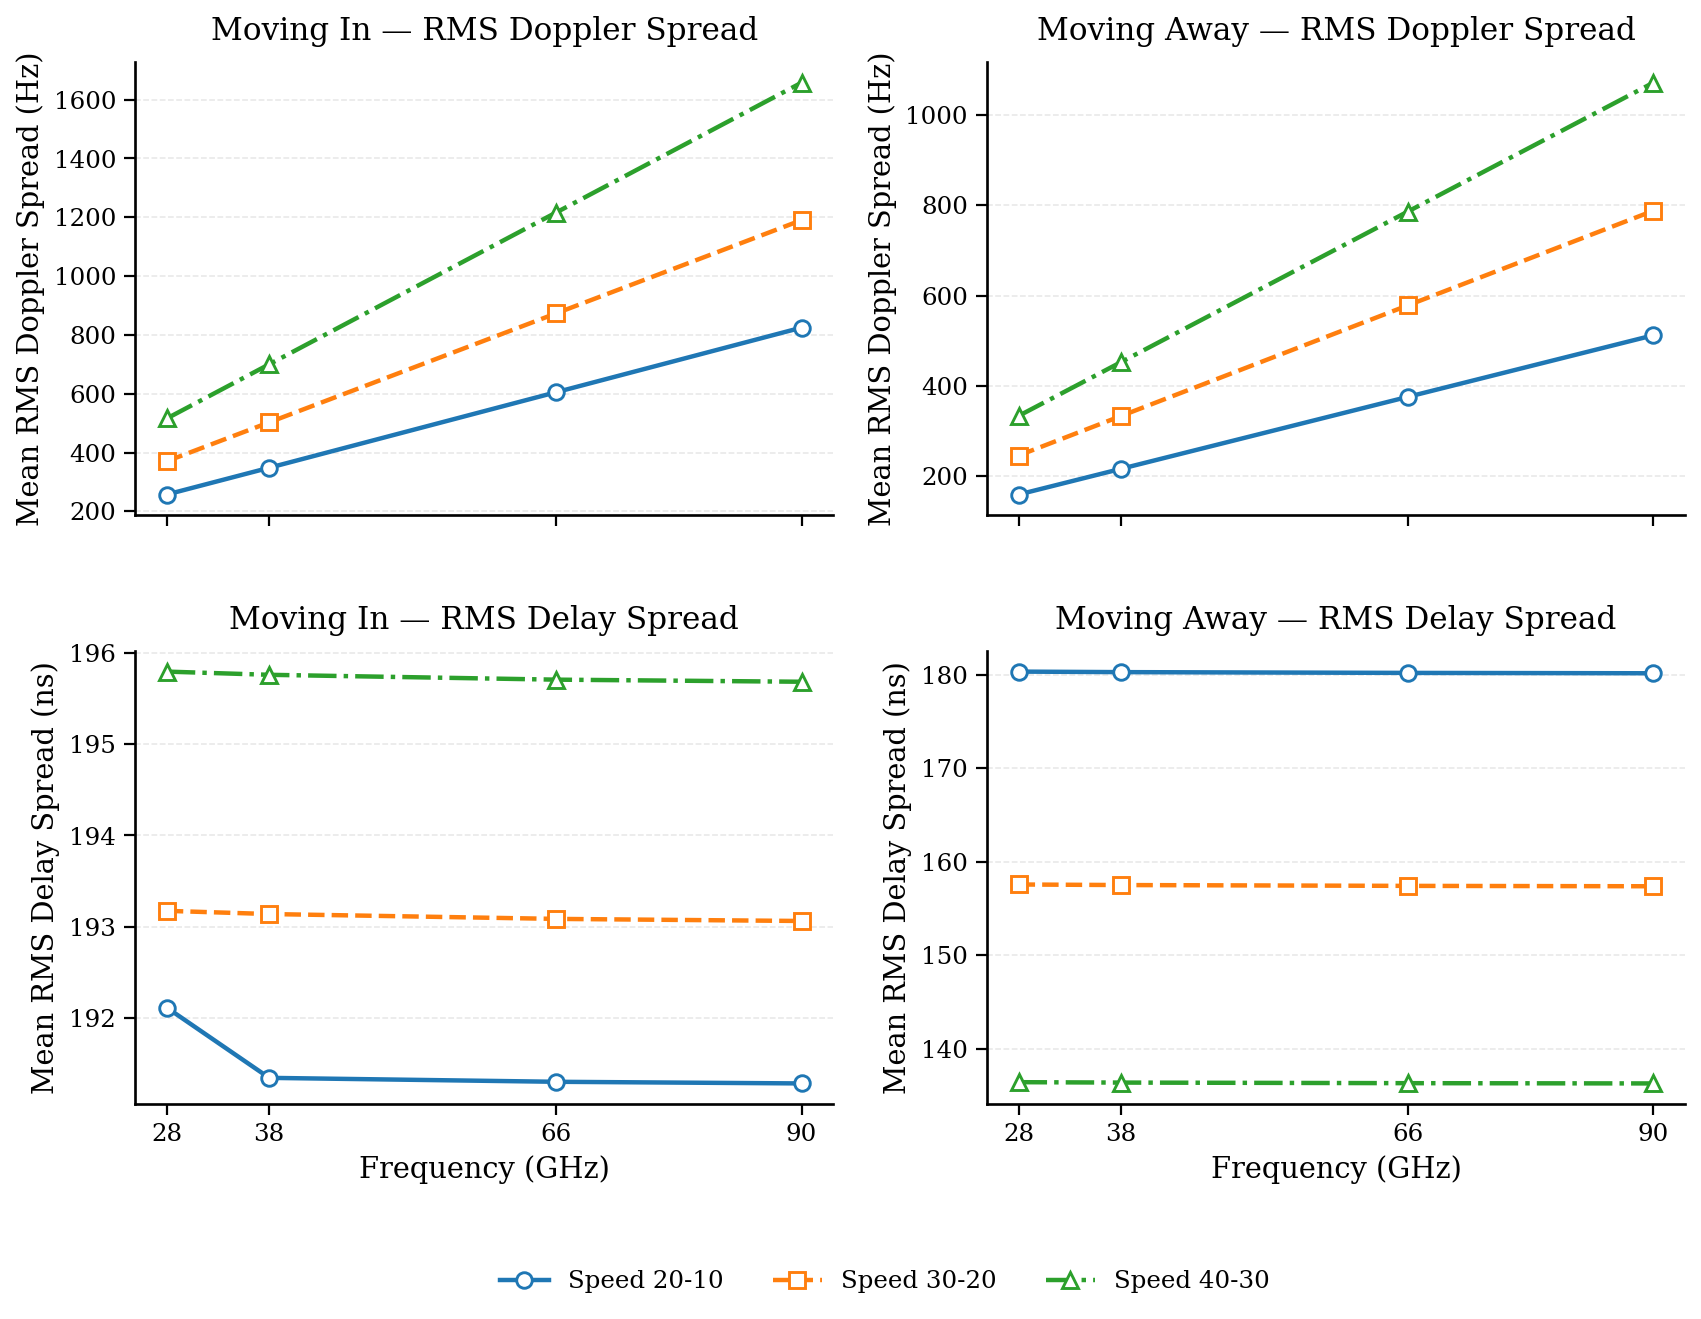

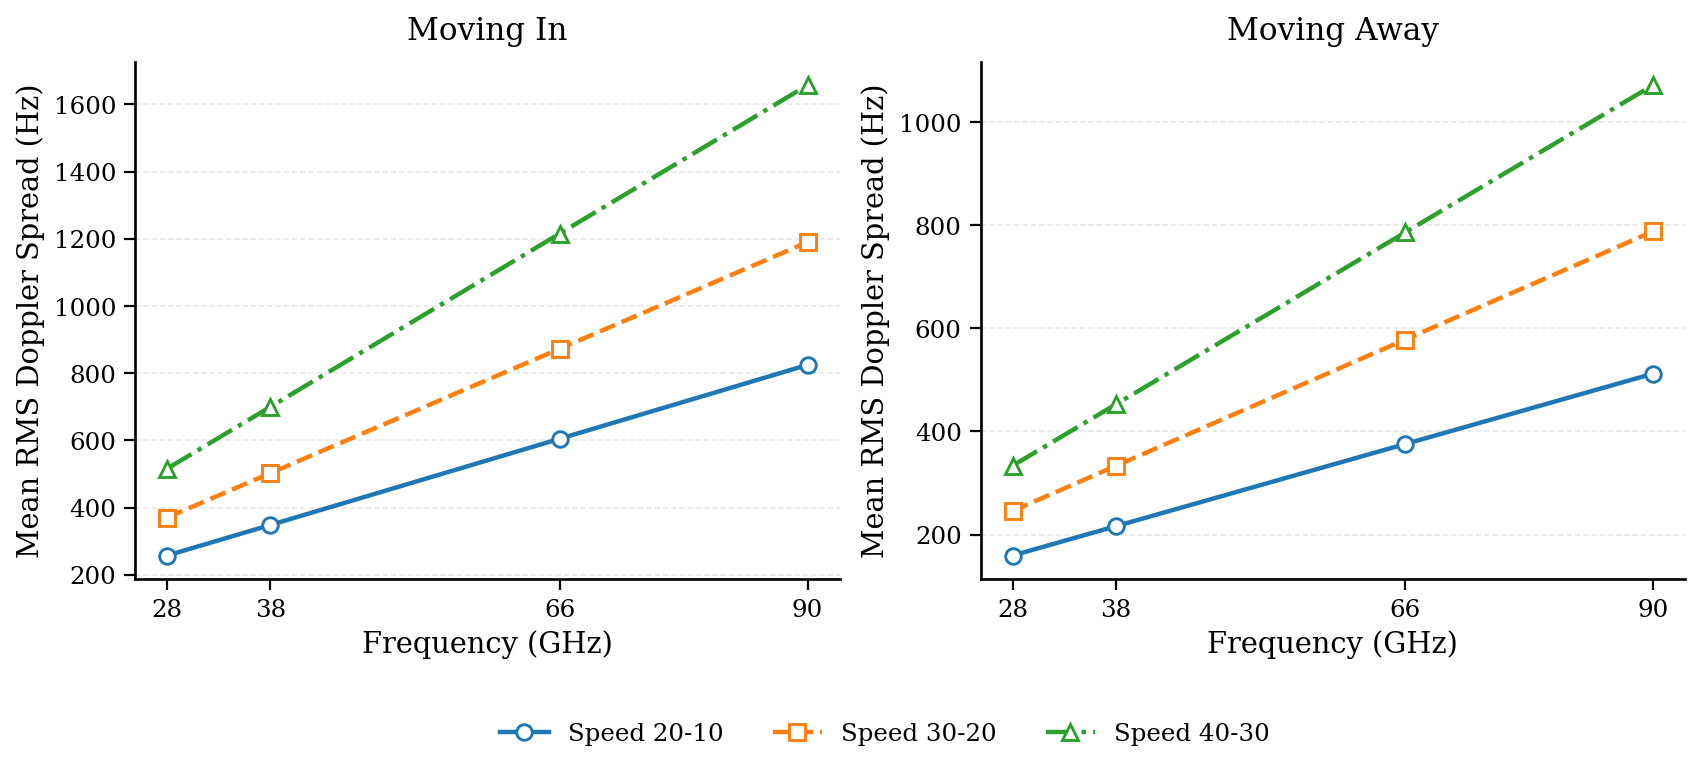

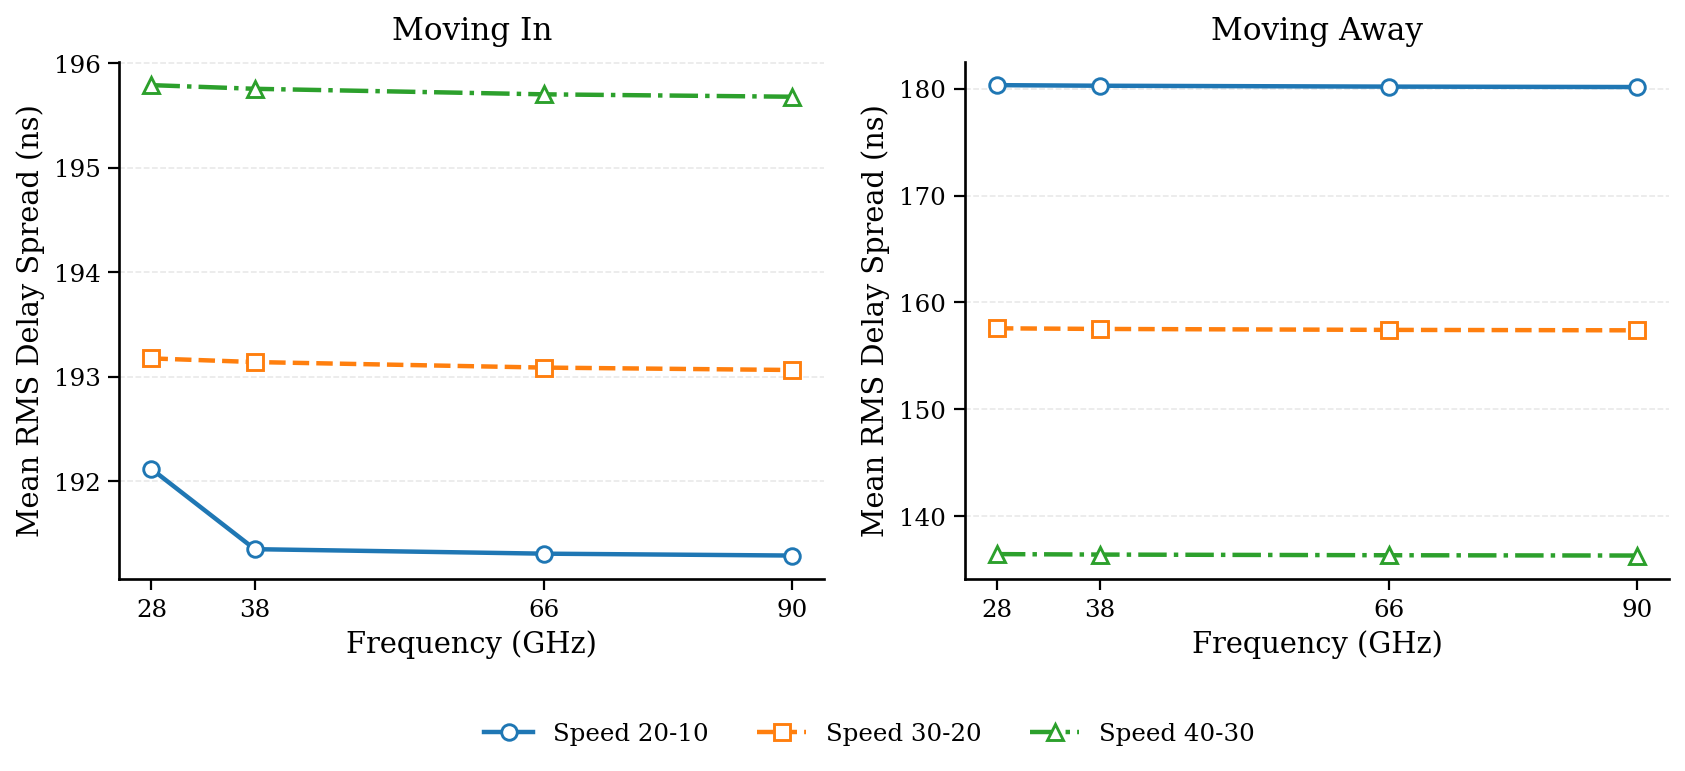


تم إنشاء الملفات التالية:
- publication_figures/Figure_1_RMS_2x2.png
- publication_figures/Figure_1_RMS_2x2.svg
- publication_figures/Figure_2_Doppler.png
- publication_figures/Figure_2_Doppler.svg
- publication_figures/Figure_3_Delay.png
- publication_figures/Figure_3_Delay.svg
- publication_figures/data_used_for_plotting.xlsx

تم ضغط جميع النتائج في: publication_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# Publication-quality plotting from detailed_phase_summary.xlsx
# ============================================================

!pip -q install openpyxl

import os
import re
import zipfile
import warnings
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1) Upload file
# ------------------------------------------------------------
print("ارفع ملف detailed_phase_summary.xlsx")
uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("لم يتم رفع أي ملف.")

input_file = list(uploaded.keys())[0]
print(f"\nتم رفع الملف: {input_file}")

# ------------------------------------------------------------
# 2) Read workbook / sheet
# ------------------------------------------------------------
xlsx = pd.ExcelFile(input_file)

if "Detailed_Summary" in xlsx.sheet_names:
    sheet_name = "Detailed_Summary"
else:
    sheet_name = xlsx.sheet_names[0]

df = pd.read_excel(input_file, sheet_name=sheet_name)

# ------------------------------------------------------------
# 3) Validate columns
# ------------------------------------------------------------
required_cols = [
    "Frequency (GHz)",
    "Speed",
    "Scenario",
    "Mean RMS Doppler Spread (Hz)",
    "Mean RMS Delay Spread (ns)"
]

missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise ValueError(f"الأعمدة التالية غير موجودة في الملف: {missing_cols}")

# ------------------------------------------------------------
# 4) Clean and standardize data
# ------------------------------------------------------------
def normalize_scenario(x):
    if pd.isna(x):
        return None
    s = str(x).strip().lower().replace(" ", "_")
    if s in ["movingin", "move_in", "in"]:
        return "moving_in"
    if s in ["movingaway", "move_away", "away"]:
        return "moving_away"
    return s

df = df.copy()
df["Scenario"] = df["Scenario"].apply(normalize_scenario)
df["Speed"] = df["Speed"].astype(str).str.strip()
df["Frequency (GHz)"] = pd.to_numeric(df["Frequency (GHz)"], errors="coerce")
df["Mean RMS Doppler Spread (Hz)"] = pd.to_numeric(df["Mean RMS Doppler Spread (Hz)"], errors="coerce")
df["Mean RMS Delay Spread (ns)"] = pd.to_numeric(df["Mean RMS Delay Spread (ns)"], errors="coerce")

df = df.dropna(subset=[
    "Frequency (GHz)",
    "Speed",
    "Scenario",
    "Mean RMS Doppler Spread (Hz)",
    "Mean RMS Delay Spread (ns)"
])

df = df[df["Scenario"].isin(["moving_in", "moving_away"])].copy()

if df.empty:
    raise ValueError("لا توجد بيانات صالحة بعد التنظيف.")

df = df.drop_duplicates(subset=["Frequency (GHz)", "Speed", "Scenario"])

expected_freq_order = [28, 38, 66, 90]
expected_speed_order = ["20-10", "30-20", "40-30"]
scenario_order = ["moving_in", "moving_away"]

freq_present = sorted(df["Frequency (GHz)"].dropna().unique().tolist())
freq_order = [f for f in expected_freq_order if f in freq_present] + [f for f in freq_present if f not in expected_freq_order]

speed_present = df["Speed"].dropna().unique().tolist()
speed_order = [s for s in expected_speed_order if s in speed_present] + [s for s in speed_present if s not in expected_speed_order]

df["Frequency (GHz)"] = pd.Categorical(df["Frequency (GHz)"], categories=freq_order, ordered=True)
df["Speed"] = pd.Categorical(df["Speed"], categories=speed_order, ordered=True)
df["Scenario"] = pd.Categorical(df["Scenario"], categories=scenario_order, ordered=True)

df = df.sort_values(["Scenario", "Speed", "Frequency (GHz)"]).reset_index(drop=True)

# ------------------------------------------------------------
# 5) Matplotlib style for publication
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif", "Times New Roman", "Times"],
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 1.2,
    "figure.dpi": 160,
    "savefig.dpi": 600,
})

marker_map = {
    "20-10": "o",
    "30-20": "s",
    "40-30": "^"
}

linestyle_map = {
    "20-10": "-",
    "30-20": "--",
    "40-30": "-."
}

scenario_title = {
    "moving_in": "Moving In",
    "moving_away": "Moving Away"
}

def stylize_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", direction="out", width=1.0, length=5)
    ax.grid(True, axis="y", linestyle="--", linewidth=0.7, alpha=0.30)
    ax.set_axisbelow(True)

def save_figure_all_formats(fig, out_dir, base_name):
    png_path = out_dir / f"{base_name}.png"
    svg_path = out_dir / f"{base_name}.svg"

    fig.savefig(png_path, bbox_inches="tight", dpi=600)
    fig.savefig(svg_path, bbox_inches="tight", format="svg")

    return [png_path, svg_path]

# ------------------------------------------------------------
# 6) Output directory
# ------------------------------------------------------------
out_dir = Path("publication_figures")
out_dir.mkdir(exist_ok=True)

# ------------------------------------------------------------
# 7) Figure 1: 2x2 combined figure
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.8), sharex=True)

for col_idx, scenario in enumerate(scenario_order):
    df_s = df[df["Scenario"] == scenario].copy()

    # Top row: Doppler
    ax = axes[0, col_idx]
    for speed in speed_order:
        temp = df_s[df_s["Speed"] == speed].sort_values("Frequency (GHz)")
        if temp.empty:
            continue

        x_vals = temp["Frequency (GHz)"].astype(float).tolist()
        y_vals = temp["Mean RMS Doppler Spread (Hz)"].tolist()

        ax.plot(
            x_vals,
            y_vals,
            marker=marker_map.get(str(speed), "o"),
            linestyle=linestyle_map.get(str(speed), "-"),
            linewidth=2.0,
            markersize=7,
            markerfacecolor="white",
            markeredgewidth=1.3,
            label=f"Speed {speed}"
        )

    ax.set_title(f"{scenario_title[str(scenario)]} — RMS Doppler Spread", pad=10)
    ax.set_ylabel("Mean RMS Doppler Spread (Hz)")
    ax.set_xticks(freq_order)
    stylize_axis(ax)

    # Bottom row: Delay
    ax = axes[1, col_idx]
    for speed in speed_order:
        temp = df_s[df_s["Speed"] == speed].sort_values("Frequency (GHz)")
        if temp.empty:
            continue

        x_vals = temp["Frequency (GHz)"].astype(float).tolist()
        y_vals = temp["Mean RMS Delay Spread (ns)"].tolist()

        ax.plot(
            x_vals,
            y_vals,
            marker=marker_map.get(str(speed), "o"),
            linestyle=linestyle_map.get(str(speed), "-"),
            linewidth=2.0,
            markersize=7,
            markerfacecolor="white",
            markeredgewidth=1.3,
            label=f"Speed {speed}"
        )

    ax.set_title(f"{scenario_title[str(scenario)]} — RMS Delay Spread", pad=10)
    ax.set_xlabel("Frequency (GHz)")
    ax.set_ylabel("Mean RMS Delay Spread (ns)")
    ax.set_xticks(freq_order)
    stylize_axis(ax)

handles, labels = axes[0, 0].get_legend_handles_labels()
if handles:
    fig.legend(
        handles, labels,
        loc="lower center",
        ncol=len(speed_order),
        frameon=False,
        bbox_to_anchor=(0.5, -0.01)
    )

plt.subplots_adjust(wspace=0.22, hspace=0.30, bottom=0.14)
plt.show()

saved_files = []
saved_files += save_figure_all_formats(fig, out_dir, "Figure_1_RMS_2x2")
plt.close(fig)

# ------------------------------------------------------------
# 8) Figure 2: Doppler only (1x2)
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.9), sharex=True)

for i, scenario in enumerate(scenario_order):
    ax = axes[i]
    df_s = df[df["Scenario"] == scenario].copy()

    for speed in speed_order:
        temp = df_s[df_s["Speed"] == speed].sort_values("Frequency (GHz)")
        if temp.empty:
            continue

        ax.plot(
            temp["Frequency (GHz)"].astype(float).tolist(),
            temp["Mean RMS Doppler Spread (Hz)"].tolist(),
            marker=marker_map.get(str(speed), "o"),
            linestyle=linestyle_map.get(str(speed), "-"),
            linewidth=2.0,
            markersize=7,
            markerfacecolor="white",
            markeredgewidth=1.3,
            label=f"Speed {speed}"
        )

    ax.set_title(f"{scenario_title[str(scenario)]}", pad=10)
    ax.set_xlabel("Frequency (GHz)")
    ax.set_ylabel("Mean RMS Doppler Spread (Hz)")
    ax.set_xticks(freq_order)
    stylize_axis(ax)

handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(
        handles, labels,
        loc="lower center",
        ncol=len(speed_order),
        frameon=False,
        bbox_to_anchor=(0.5, -0.02)
    )

plt.subplots_adjust(wspace=0.20, bottom=0.22)
plt.show()

saved_files += save_figure_all_formats(fig, out_dir, "Figure_2_Doppler")
plt.close(fig)

# ------------------------------------------------------------
# 9) Figure 3: Delay only (1x2)
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.9), sharex=True)

for i, scenario in enumerate(scenario_order):
    ax = axes[i]
    df_s = df[df["Scenario"] == scenario].copy()

    for speed in speed_order:
        temp = df_s[df_s["Speed"] == speed].sort_values("Frequency (GHz)")
        if temp.empty:
            continue

        ax.plot(
            temp["Frequency (GHz)"].astype(float).tolist(),
            temp["Mean RMS Delay Spread (ns)"].tolist(),
            marker=marker_map.get(str(speed), "o"),
            linestyle=linestyle_map.get(str(speed), "-"),
            linewidth=2.0,
            markersize=7,
            markerfacecolor="white",
            markeredgewidth=1.3,
            label=f"Speed {speed}"
        )

    ax.set_title(f"{scenario_title[str(scenario)]}", pad=10)
    ax.set_xlabel("Frequency (GHz)")
    ax.set_ylabel("Mean RMS Delay Spread (ns)")
    ax.set_xticks(freq_order)
    stylize_axis(ax)

handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(
        handles, labels,
        loc="lower center",
        ncol=len(speed_order),
        frameon=False,
        bbox_to_anchor=(0.5, -0.02)
    )

plt.subplots_adjust(wspace=0.20, bottom=0.22)
plt.show()

saved_files += save_figure_all_formats(fig, out_dir, "Figure_3_Delay")
plt.close(fig)

# ------------------------------------------------------------
# 10) Save cleaned data used for plotting
# ------------------------------------------------------------
cleaned_data_path = out_dir / "data_used_for_plotting.xlsx"
with pd.ExcelWriter(cleaned_data_path, engine="openpyxl") as writer:
    df.to_excel(writer, sheet_name="Plot_Data", index=False)
saved_files.append(cleaned_data_path)

# ------------------------------------------------------------
# 11) Zip all outputs
# ------------------------------------------------------------
zip_path = "publication_figures.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for f in saved_files:
        zf.write(f, arcname=f.name)

print("\nتم إنشاء الملفات التالية:")
for f in saved_files:
    print("-", f)

print(f"\nتم ضغط جميع النتائج في: {zip_path}")

# ------------------------------------------------------------
# 12) Download ZIP
# ------------------------------------------------------------
files.download(zip_path)

ارفع ملفات Excel الخاصة بالـ Path Loss


Saving Moving away.xlsx to Moving away.xlsx
Saving Moving in.xlsx to Moving in.xlsx

تم رفع الملفات التالية:
- Moving away.xlsx
- Moving in.xlsx


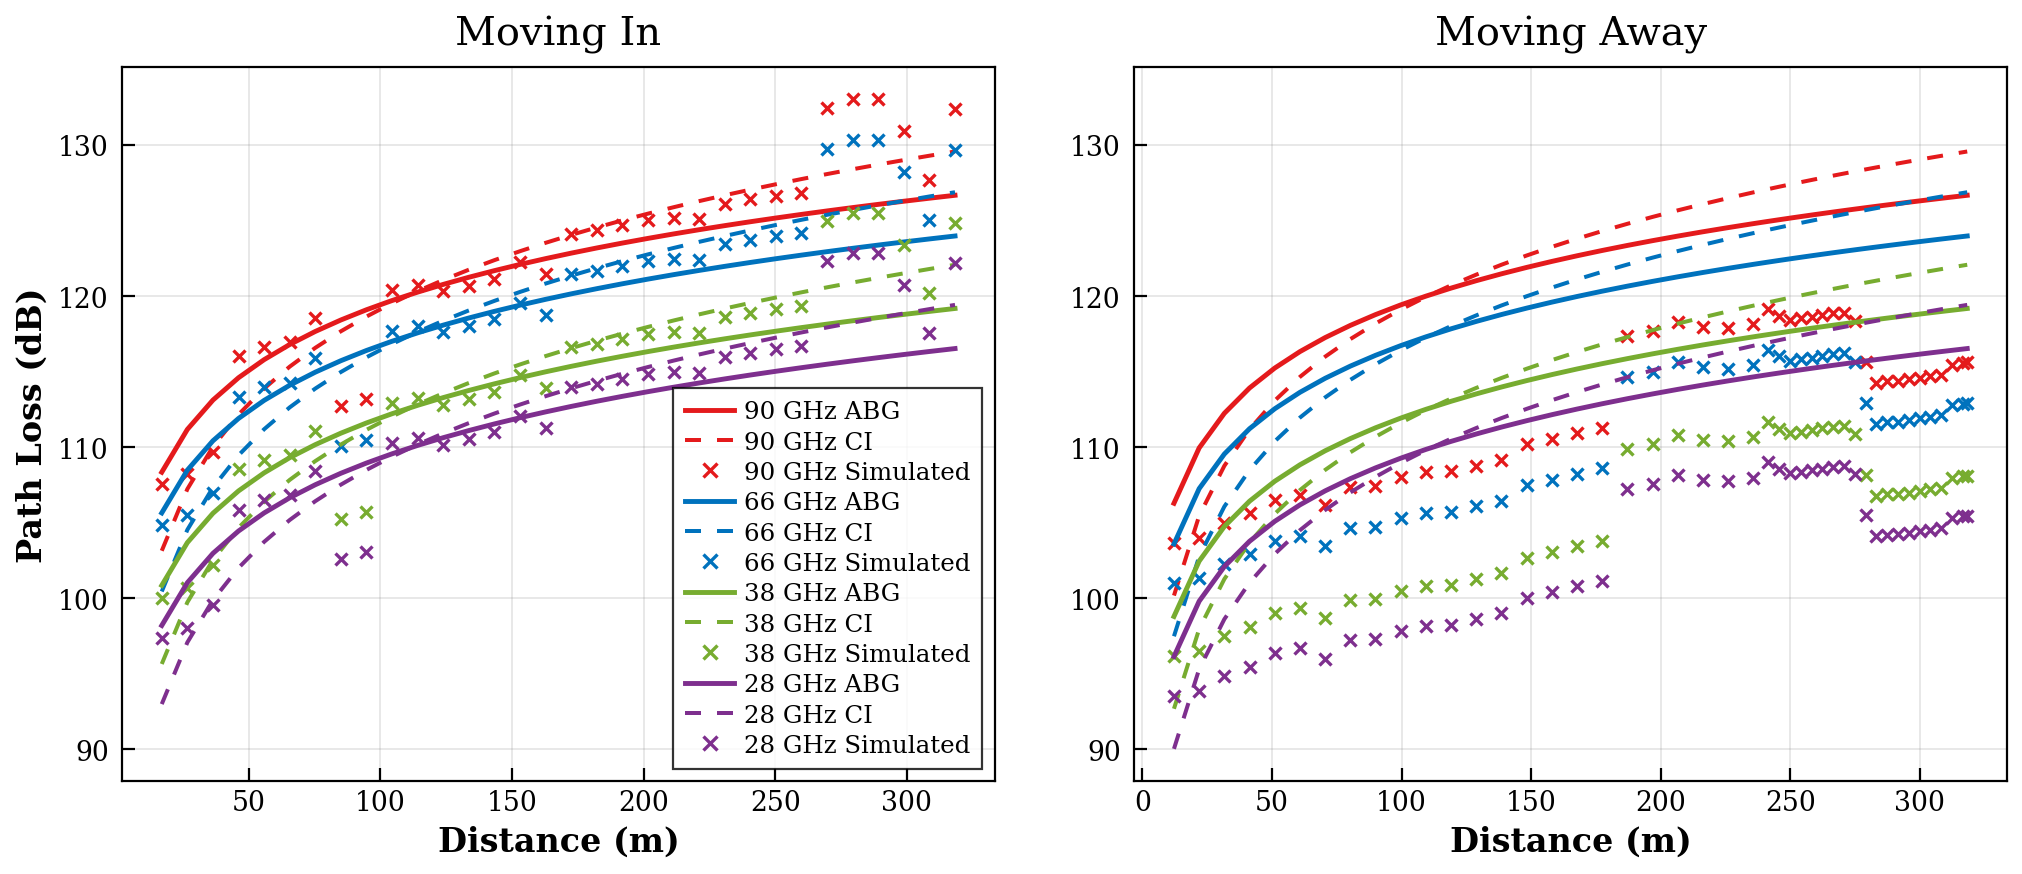


تم إنشاء الملفات التالية:
- path_loss_matched_style_figures/UnknownSpeed_matched_style_pathloss.png
- path_loss_matched_style_figures/UnknownSpeed_matched_style_pathloss.svg
- path_loss_matched_style_figures/plot_report.xlsx

تم ضغط جميع النتائج في: path_loss_matched_style_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# Publication-quality Path Loss plotting
# Style matched to the provided example
# Left  subplot = Moving In
# Right subplot = Moving Away
# Colors  -> Frequency
# ABG     -> solid line
# CI      -> dashed line
# Simulated -> x markers only
# Output: PNG + SVG
# Background: white
# ============================================================

!pip -q install openpyxl

import re
import zipfile
import warnings
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from google.colab import files

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 0) Background color
# ------------------------------------------------------------
BG_COLOR = "#ffffff"

# ------------------------------------------------------------
# 1) Upload Excel files
# ------------------------------------------------------------
print("ارفع ملفات Excel الخاصة بالـ Path Loss")
uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("لم يتم رفع أي ملف.")

input_files = list(uploaded.keys())

print("\nتم رفع الملفات التالية:")
for f in input_files:
    print("-", f)

# ------------------------------------------------------------
# 2) Matplotlib style
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.titlesize": 18,
    "axes.labelsize": 15,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "axes.linewidth": 1.0,
    "figure.dpi": 160,
    "savefig.dpi": 600,
    "figure.facecolor": BG_COLOR,
    "axes.facecolor": BG_COLOR,
    "savefig.facecolor": BG_COLOR,
    "savefig.edgecolor": BG_COLOR,
})

# ------------------------------------------------------------
# 3) Fixed styles
# ------------------------------------------------------------
FREQ_STYLE = {
    90: {"color": "#e41a1c", "marker": "x"},
    66: {"color": "#0072BD", "marker": "x"},
    38: {"color": "#77AC30", "marker": "x"},
    28: {"color": "#7E2F8E", "marker": "x"},
}

MODEL_STYLE = {
    "ABG": {
        "linestyle": "-",
        "linewidth": 2.2,
        "marker": None,
        "markersize": 0
    },
    "CI": {
        "linestyle": (0, (4, 4)),
        "linewidth": 1.8,
        "marker": None,
        "markersize": 0
    },
    "Simulated": {
        "linestyle": "None",
        "linewidth": 0,
        "marker": "x",
        "markersize": 5.0
    }
}

EXPECTED_FREQ_ORDER = [90, 66, 38, 28]
MODEL_ORDER = ["ABG", "CI", "Simulated"]
SCENARIO_ORDER = ["Moving In", "Moving Away"]

# ------------------------------------------------------------
# 4) Helper functions
# ------------------------------------------------------------
def normalize_columns(columns):
    cols = []
    for c in columns:
        c = str(c).replace("\n", " ").strip()
        c = re.sub(r"\s+", " ", c)
        cols.append(c)
    return cols

def parse_file_metadata(filename):
    stem = Path(filename).stem.lower()

    speed_match = re.search(r"(\d+\s*-\s*\d+)", stem)
    speed = speed_match.group(1).replace(" ", "") if speed_match else "UnknownSpeed"

    if "moving away" in stem or "moving_away" in stem or "movingaway" in stem:
        scenario = "Moving Away"
    elif "moving in" in stem or "moving_in" in stem or "movingin" in stem:
        scenario = "Moving In"
    else:
        scenario = "UnknownScenario"

    return speed, scenario

def detect_distance_column(df):
    candidates = [
        "D", "d", "Distance", "distance", "Dist", "dist",
        "Distance (m)", "distance (m)", "D (m)", "d (m)"
    ]
    for c in df.columns:
        if str(c).strip() in candidates:
            return c
    return df.columns[0]

def detect_frequency(col_name):
    txt = str(col_name).lower()
    m = re.search(r"(\d+)\s*ghz", txt)
    if m:
        return int(m.group(1))
    return None

def detect_model(col_name):
    txt = str(col_name).lower()

    if "abg" in txt:
        return "ABG"
    if re.search(r"\bci\b", txt):
        return "CI"
    if "simulated" in txt or "simulate" in txt or "simulted" in txt or "simul" in txt:
        return "Simulated"

    return None

def extract_mapping(df):
    distance_col = detect_distance_column(df)
    mapping = {m: {} for m in MODEL_ORDER}

    for col in df.columns:
        if col == distance_col:
            continue

        freq = detect_frequency(col)
        model = detect_model(col)

        if freq is None or model is None:
            continue

        mapping[model][freq] = col

    return distance_col, mapping

def stylize_axis(ax):
    ax.set_facecolor(BG_COLOR)
    ax.patch.set_alpha(1.0)
    ax.grid(True, which="major", color="gray", alpha=0.20, linestyle="-", linewidth=0.8)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_linewidth(1.0)

    ax.tick_params(axis="both", which="major", direction="in", length=6, width=1.0)
    ax.tick_params(axis="both", which="minor", direction="in", length=3, width=0.8)

def save_png_svg(fig, out_dir, base_name):
    png_path = out_dir / f"{base_name}.png"
    svg_path = out_dir / f"{base_name}.svg"

    fig.savefig(
        png_path,
        dpi=600,
        bbox_inches="tight",
        facecolor=BG_COLOR,
        edgecolor=BG_COLOR,
        transparent=False
    )

    fig.savefig(
        svg_path,
        format="svg",
        bbox_inches="tight",
        facecolor=BG_COLOR,
        edgecolor=BG_COLOR,
        transparent=False
    )

    return [png_path, svg_path]

def speed_sort_key(speed_text):
    nums = re.findall(r"\d+", str(speed_text))
    if len(nums) >= 2:
        return (int(nums[0]), int(nums[1]))
    return (999, 999)

# ------------------------------------------------------------
# 5) Read all files and organize data
# ------------------------------------------------------------
data = {}
report_rows = []

for file_name in input_files:
    try:
        speed, scenario = parse_file_metadata(file_name)

        xlsx = pd.ExcelFile(file_name)
        sheet_name = xlsx.sheet_names[0]
        df = pd.read_excel(file_name, sheet_name=sheet_name)
        df.columns = normalize_columns(df.columns)

        distance_col, mapping = extract_mapping(df)

        df = df.copy()
        df[distance_col] = pd.to_numeric(df[distance_col], errors="coerce")

        all_y_cols = []
        for model in MODEL_ORDER:
            all_y_cols.extend(list(mapping[model].values()))

        for col in all_y_cols:
            df[col] = pd.to_numeric(df[col], errors="coerce")

        df = df.dropna(subset=[distance_col]).sort_values(distance_col).reset_index(drop=True)

        if speed not in data:
            data[speed] = {}
        if scenario not in data[speed]:
            data[speed][scenario] = {m: {} for m in MODEL_ORDER}

        for model in MODEL_ORDER:
            for freq, col in mapping[model].items():
                temp = df[[distance_col, col]].dropna().copy()
                temp.columns = ["Distance", "Path Loss"]
                if not temp.empty:
                    data[speed][scenario][model][freq] = temp

        detected_freqs = sorted(
            set(freq for model in MODEL_ORDER for freq in mapping[model].keys()),
            reverse=True
        )

        report_rows.append({
            "Source File": file_name,
            "Sheet Used": sheet_name,
            "Speed": speed,
            "Scenario": scenario,
            "Distance Column": distance_col,
            "Detected Models": ", ".join([m for m in MODEL_ORDER if len(mapping[m]) > 0]),
            "Detected Frequencies": ", ".join(str(f) for f in detected_freqs)
        })

    except Exception as e:
        print(f"\nخطأ في الملف {file_name}: {e}")

if len(data) == 0:
    raise ValueError("لم يتم استخراج بيانات صالحة من الملفات.")

# ------------------------------------------------------------
# 6) Output folder
# ------------------------------------------------------------
out_dir = Path("path_loss_matched_style_figures")
out_dir.mkdir(exist_ok=True)

saved_files = []

# ------------------------------------------------------------
# 7) Create one figure per speed
# ------------------------------------------------------------
sorted_speeds = sorted(data.keys(), key=speed_sort_key)

for speed in sorted_speeds:

    has_any = False
    for scenario in SCENARIO_ORDER:
        if scenario in data[speed]:
            for model in MODEL_ORDER:
                if len(data[speed][scenario][model]) > 0:
                    has_any = True

    if not has_any:
        continue

    fig, axes = plt.subplots(1, 2, figsize=(15.2, 5.8), sharey=True)
    fig.patch.set_facecolor(BG_COLOR)
    fig.patch.set_alpha(1.0)

    for ax in axes:
        ax.set_facecolor(BG_COLOR)
        ax.patch.set_alpha(1.0)

    for i, (ax, scenario) in enumerate(zip(axes, SCENARIO_ORDER)):
        ax.set_title(scenario, pad=10)

        if scenario in data[speed]:
            scenario_data = data[speed][scenario]

            for freq in EXPECTED_FREQ_ORDER:
                if freq not in FREQ_STYLE:
                    continue

                color = FREQ_STYLE[freq]["color"]
                sim_marker = FREQ_STYLE[freq]["marker"]

                # ABG
                if freq in scenario_data["ABG"]:
                    temp = scenario_data["ABG"][freq]
                    ax.plot(
                        temp["Distance"].values,
                        temp["Path Loss"].values,
                        color=color,
                        linestyle=MODEL_STYLE["ABG"]["linestyle"],
                        linewidth=MODEL_STYLE["ABG"]["linewidth"]
                    )

                # CI
                if freq in scenario_data["CI"]:
                    temp = scenario_data["CI"][freq]
                    ax.plot(
                        temp["Distance"].values,
                        temp["Path Loss"].values,
                        color=color,
                        linestyle=MODEL_STYLE["CI"]["linestyle"],
                        linewidth=MODEL_STYLE["CI"]["linewidth"]
                    )

                # Simulated
                if freq in scenario_data["Simulated"]:
                    temp = scenario_data["Simulated"][freq]
                    ax.plot(
                        temp["Distance"].values,
                        temp["Path Loss"].values,
                        linestyle="None",
                        marker=sim_marker,
                        color=color,
                        markersize=MODEL_STYLE["Simulated"]["markersize"],
                        markeredgewidth=1.5
                    )

        ax.set_xlabel("Distance (m)", fontweight="bold")

        if i == 0:
            ax.set_ylabel("Path Loss (dB)", fontweight="bold")
        else:
            ax.set_ylabel("")

        stylize_axis(ax)

    # Show Y ticks also on Moving Away
    axes[1].tick_params(axis="y", which="both", labelleft=True, pad=6)
    axes[1].yaxis.set_ticks_position("left")
    axes[0].tick_params(axis="y", which="both", pad=6)

    # Legend inside Moving In
    legend_handles = []
    for freq in EXPECTED_FREQ_ORDER:
        if freq not in FREQ_STYLE:
            continue

        color = FREQ_STYLE[freq]["color"]
        marker = FREQ_STYLE[freq]["marker"]

        legend_handles.append(
            Line2D([0], [0],
                   color=color,
                   linestyle=MODEL_STYLE["ABG"]["linestyle"],
                   linewidth=MODEL_STYLE["ABG"]["linewidth"],
                   label=f"{freq} GHz ABG")
        )
        legend_handles.append(
            Line2D([0], [0],
                   color=color,
                   linestyle=MODEL_STYLE["CI"]["linestyle"],
                   linewidth=MODEL_STYLE["CI"]["linewidth"],
                   label=f"{freq} GHz CI")
        )
        legend_handles.append(
            Line2D([0], [0],
                   color=color,
                   linestyle="None",
                   marker=marker,
                   markersize=6,
                   markeredgewidth=1.5,
                   label=f"{freq} GHz Simulated")
        )

    axes[0].legend(
        handles=legend_handles,
        loc="lower right",
        frameon=True,
        fancybox=False,
        edgecolor="black",
        facecolor="white",
        borderpad=0.5,
        labelspacing=0.3,
        handlelength=2.0,
        handletextpad=0.4
    )

    plt.subplots_adjust(wspace=0.16)
    plt.show()

    base_name = f"{speed}_matched_style_pathloss"
    saved = save_png_svg(fig, out_dir, base_name)
    saved_files.extend(saved)
    plt.close(fig)

# ------------------------------------------------------------
# 8) Save report
# ------------------------------------------------------------
if len(report_rows) > 0:
    report_df = pd.DataFrame(report_rows)
    report_path = out_dir / "plot_report.xlsx"
    report_df.to_excel(report_path, index=False)
    saved_files.append(report_path)

# ------------------------------------------------------------
# 9) Zip all outputs
# ------------------------------------------------------------
if len(saved_files) == 0:
    raise ValueError("لم يتم إنشاء أي رسومات. تحقق من بنية الملفات.")

zip_path = "path_loss_matched_style_figures.zip"

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for f in saved_files:
        zf.write(f, arcname=f.name)

print("\nتم إنشاء الملفات التالية:")
for f in saved_files:
    print("-", f)

print(f"\nتم ضغط جميع النتائج في: {zip_path}")

# ------------------------------------------------------------
# 10) Download ZIP
# ------------------------------------------------------------
files.download(zip_path)